# The Growing Footprint of Fashion in Norway (TEP4222, NTNU)

This code represents the final project of the group 2 of the TEP4222. The students are: Lena Dehli and Léo Liberkowski

This file uses the following database:
- exiobase 3 v3.9.5: https://zenodo.org/records/14869924

## Importation of the packages

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from extraction_data import *

## Importation of the data

The use of `pymrio` was not allowed in this project, so the EXIOBASE matrices are parsed by hand (see `extraction_data.py`).

In [2]:
year = list(range(1995, 2023)) # years of interest in the study, to be changed if needed*
matrix_interest = ['Z', 'Y', 'x', 'F_land', 'F_water', 'F_airem']

Run the notebook from the project root, with the raw EXIOBASE files in a `data/` folder:

In [ ]:
# Root folder of the project (the notebook is run from it)
path_file = str(Path.cwd())

We will create a dictionnary which will contain all the matrix we need:

In [4]:
exio_meta_dict = {}

We decided to focus on the industry of clothing. Therefore, we will work on the ixi files.

In [5]:
for i in range (len(year)):
    # No land data for 2022
    print(year[i])
    if year[i] != 2022:
        Z_matrix_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/Z.txt'
        Y_matrix_path = path_file + '/data/IOT_'+ str(year[i]) + '_ixi/Y.txt'
        x_matrix_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/x.txt'
        F_land_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/land/F.txt'  
        F_water_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/water/F.txt'
        F_airem_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/air_emissions/F.txt'    
        # Charger le fichier sans filtrer les colonnes
        exio_meta_dict[(str(year[i]), 'Z')] = extraction_data_Z_matrix (Z_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'Y')] = extraction_data_Y_matrix (Y_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'x')] = extraction_data_x_matrix (x_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'F_land')] = extraction_data_F_land_matrix (F_land_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'F_water')] = extraction_data_F_water_matrix (F_water_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'F_airem')] = extraction_data_F_airem_matrix (F_airem_path).apply(pd.to_numeric, errors='coerce')
    else:
        Z_matrix_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/Z.txt'
        Y_matrix_path = path_file + '/data/IOT_'+ str(year[i]) + '_ixi/Y.txt'
        x_matrix_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/x.txt'  
        F_water_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/water/F.txt'
        F_airem_path = path_file + '/data/IOT_' + str(year[i]) + '_ixi/air_emissions/F.txt'    
        # Charger le fichier sans filtrer les colonnes
        exio_meta_dict[(str(year[i]), 'Z')] = extraction_data_Z_matrix (Z_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'Y')] = extraction_data_Y_matrix (Y_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'x')] = extraction_data_x_matrix (x_matrix_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'F_water')] = extraction_data_F_water_matrix (F_water_path).apply(pd.to_numeric, errors='coerce')
        exio_meta_dict[(str(year[i]), 'F_airem')] = extraction_data_F_airem_matrix (F_airem_path).apply(pd.to_numeric, errors='coerce')

1995


1996


1997


1998


1999


2000


... (18 outputs left out)

2019


2020


2021


2022


## Part 1: General Focus on the Norwegian Clothing sector in Norway

### Biggest producer in the Textile Industry

The first step of our analyze will be to have an idea on the textile industry over the world, to analyze the biggest producers and to compare their productions with Norway.

#### Comparison between top country producers in 1995 and in 2022

First, we will have a look on these top countries between 1995 and 2022, and then we will have a look on the evolution of the percentage of clothes produced in Norway through the years.

In [6]:
#We create a copy of the data for 1995 and 2022
x_1995 = exio_meta_dict[('1995','x')].copy()
x_2022 = exio_meta_dict[('2022','x')].copy()

#We filter the data to only include the rows where the second level of the index is "Manufacture of textiles (17)"
filtered_data_1995 = x_1995.loc[x_1995.index.get_level_values(1) == "Manufacture of textiles (17)"]
filtered_data_2022 = x_2022.loc[x_2022.index.get_level_values(1) == "Manufacture of textiles (17)"]

#We sort the data by the 'indout' column in descending order
sorted_data_1995 = filtered_data_1995.sort_values(by='indout', ascending=False)
sorted_data_2022 = filtered_data_2022.sort_values(by='indout', ascending=False)



Let's now show this on two graphs:

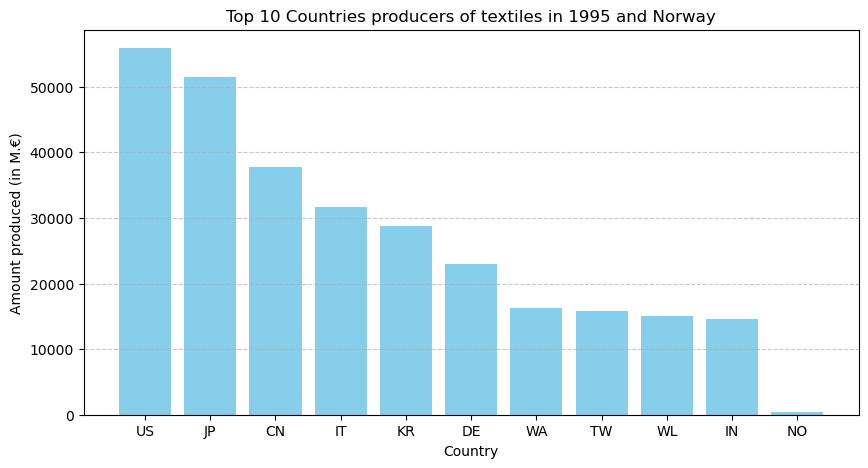

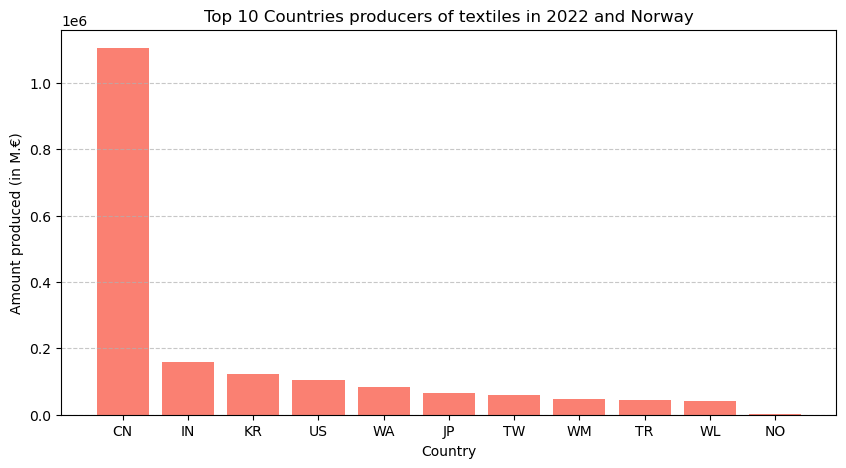

In [7]:
#We select the top 10 countries for 1995 and check if 'NO' is in the data
top_10_countries_1995 = sorted_data_1995.iloc[:10, :]  
no_data = filtered_data_1995.loc[filtered_data_1995.index.get_level_values(0) == 'NO']
if not no_data.empty and 'NO' not in top_10_countries_1995.iloc[:, 0].values:
    top_10_countries_1995 = pd.concat([top_10_countries_1995, no_data])

#We do the same for 2022
top_10_countries_2022 = sorted_data_2022.iloc[:10, :]  
no_data = filtered_data_2022.loc[filtered_data_2022.index.get_level_values(0) == 'NO']
if not no_data.empty and 'NO' not in top_10_countries_2022.iloc[:, 0].values:
    top_10_countries_2022 = pd.concat([top_10_countries_2022, no_data])


# plot the first histogram
plt.figure(figsize=(10, 5))
plt.bar(top_10_countries_1995.index.get_level_values(0), top_10_countries_1995['indout'], color='skyblue')
plt.title('Top 10 Countries producers of textiles in 1995 and Norway')
plt.xlabel('Country')
plt.ylabel('Amount produced (in M.€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# plot the second histogram
plt.figure(figsize=(10, 5))
plt.bar(top_10_countries_2022.index.get_level_values(0), top_10_countries_2022['indout'], color='salmon')
plt.title('Top 10 Countries producers of textiles in 2022 and Norway')
plt.xlabel('Country')
plt.ylabel('Amount produced (in M.€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Let's import the related data into our folder:

In [8]:
# Save the dataframes to Excel files
path_1 = path_file + '/data_processed/Part 1/top_10_countries_prod_1995.xlsx'
path_2 = path_file + '/data_processed/Part 1/top_10_countries_prod_2022.xlsx'

top_10_countries_1995.to_excel(path_1)
top_10_countries_2022.to_excel(path_2)

#### Evolution of the production of the Norwegian clothing sector

Another aspect worth noting is the evolution of the proportion of Norwegian production in relation to world production. 

In [9]:
matrix_percentage = pd.DataFrame(index = year, columns= ['Percentage of clothing and textile produced in Norway'])

# Calculate the percentage of clothing and textile produced in Norway for each year
for i in range(len(year)):
    YEAR = year[i]
    x_yeari = exio_meta_dict[(str(YEAR), 'x')].copy()
    # Calculate the percentage of clothing and textile produced in Norway for year i
    norway_data = x_yeari.loc[('NO', 'Manufacture of textiles (17)'), 'indout']
    total_data = x_yeari.loc[(slice(None), 'Manufacture of textiles (17)'),'indout'].sum()
    percentage = (norway_data / total_data) * 100
    matrix_percentage.loc[YEAR] = percentage



We can now print the related graph:

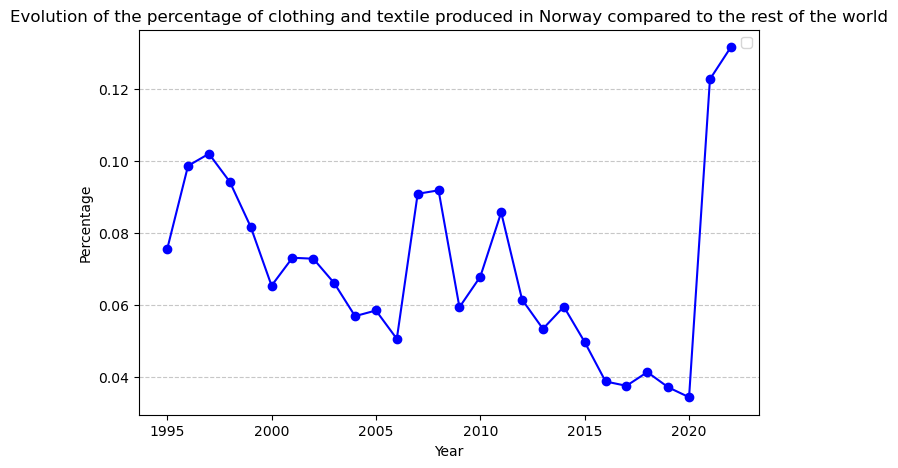

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(matrix_percentage.index, matrix_percentage['Percentage of clothing and textile produced in Norway'], marker='o', linestyle='-', color='b')
plt.title('Evolution of the percentage of clothing and textile produced in Norway compared to the rest of the world')
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

Let's import the data in our folder:

In [11]:
path_3 = path_file + '/data_processed/Part 1/evol_percentage.xlsx'

matrix_percentage.to_excel(path_3)

### Number of clothes consumed in Norway

Now that we've been able to identify general information about the global textile industry and Norway's place in it, let's focus on the Norwegian textile sector specifically.

#### Evolution of Norwegian Consumption

In [12]:
matrix_number_clothes_consumed = pd.DataFrame(index = year, columns= ['Number of clothing and textile consummed in Norway'])
# Calculate the number of clothing and textile consummed in Norway for each year
for i in range(len(year)):
    YEAR = year[i]
    Y_yeari = exio_meta_dict[(str(YEAR), 'Y')].copy()
    data = Y_yeari.loc[(slice(None), "Manufacture of textiles (17)"), ('NO', 'Final consumption expenditure by households')]
    sum_data = data.sum()
    matrix_number_clothes_consumed.loc[YEAR] = sum_data


Let's plot the graph:

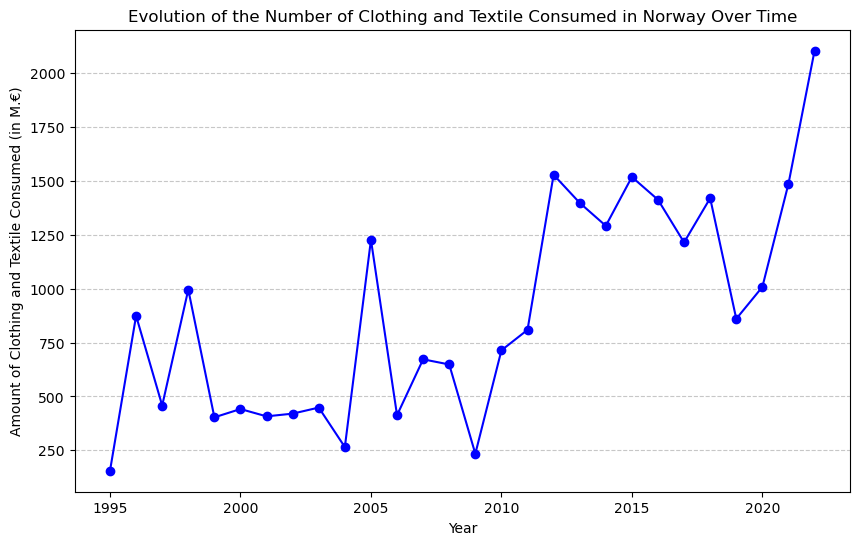

In [13]:
# Plot the Evolution of the Column Over Time
plt.figure(figsize=(10, 6))
plt.plot(matrix_number_clothes_consumed.index, matrix_number_clothes_consumed["Number of clothing and textile consummed in Norway"], marker="o", linestyle="-", color="b")
plt.title("Evolution of the Number of Clothing and Textile Consumed in Norway Over Time")
plt.xlabel("Year")
plt.ylabel("Amount of Clothing and Textile Consumed (in M.€)")
plt.grid(axis="y", linestyle="--", alpha=0.7)
plt.show()

And let's export the data:

In [14]:
path_4 = path_file + '/data_processed/Part 1/evol_number_clothes_consumed.xlsx'

matrix_number_clothes_consumed.to_excel(path_4)

#### Comparaison between Norwegian clothing consumption and european clothing consumption

To get a better overview, it might be a good idea to compare this Norwegian comparison with another, economically close, location. In this study, we have chosen to compare with the EU27 (we will keep the 27 EU countries as they are now from 1995 to 2022). 

In [15]:
# We create a list of countries in the EU
list_country_EU = ['AT', 'BE', 'BG', 'CY', 'CZ', 'DE', 'DK', 'EE', 'ES', 'FI', 'FR', 'GR', 'HR', 'HU', 'IE', 'IT', 'LT', 'LU', 'LV', 'MT', 'NL', 'PL', 'PT', 'RO', 'SE', 'SI','SK']
print(len(list_country_EU)) # check the 27 countries in the EU

27


In [16]:
matrix_number_clothes_consumed_UE = pd.DataFrame(index = year, columns= ['Number of clothing and textile consummed in the EU'])
# Calculate the number of clothing and textile consummed in the EU for each year
for i in range(len(year)):
    sum_data = 0
    for j in range(len(list_country_EU)):
        Y_yearib = exio_meta_dict[(str(year[i]), 'Y')].copy()
        sum_data+= Y_yearib.loc[(slice(None), "Manufacture of textiles (17)"), (list_country_EU[j], 'Final consumption expenditure by households')].sum()
    matrix_number_clothes_consumed_UE.loc[year[i]] = sum_data


Let's plot the difference between Norway and the EU:

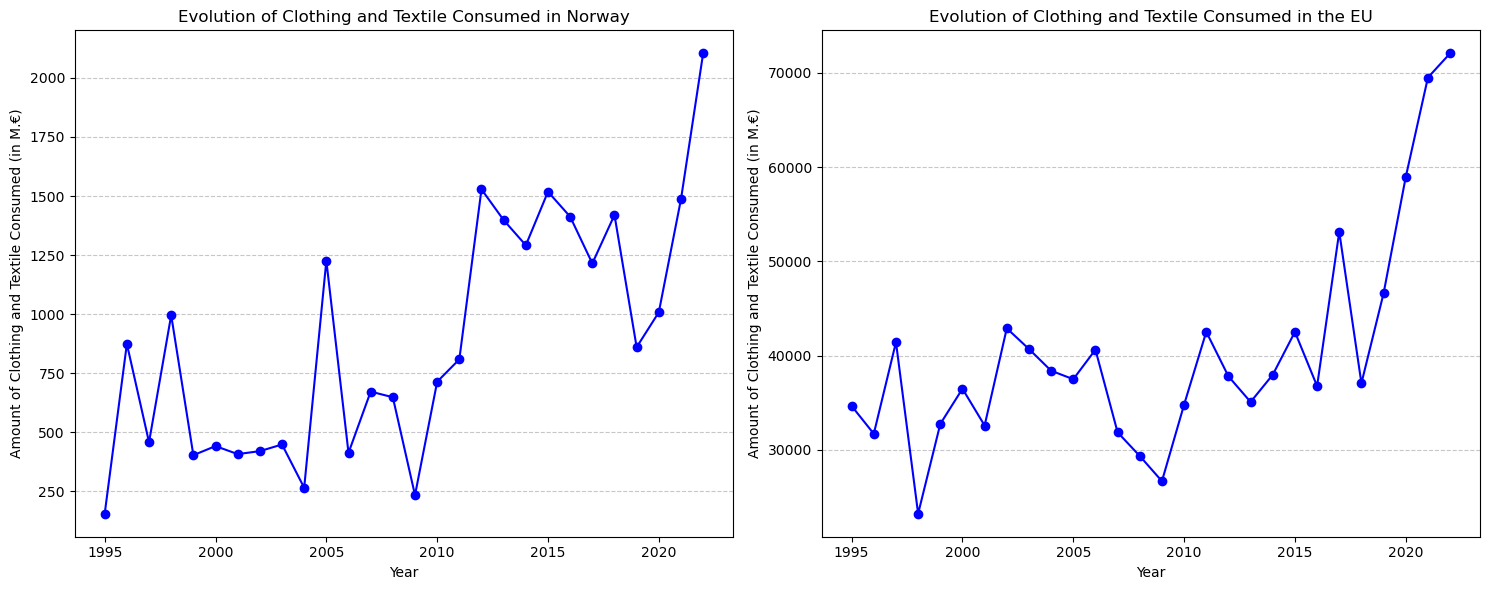

In [17]:
# Create subplots with 1 row and 2 columns
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot for Norway
axes[0].plot(matrix_number_clothes_consumed.index, 
             matrix_number_clothes_consumed["Number of clothing and textile consummed in Norway"], 
             marker="o", linestyle="-", color="b")
axes[0].set_title("Evolution of Clothing and Textile Consumed in Norway")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Amount of Clothing and Textile Consumed (in M.€)")
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

# Plot for the EU
axes[1].plot(matrix_number_clothes_consumed_UE.index, 
             matrix_number_clothes_consumed_UE["Number of clothing and textile consummed in the EU"], 
             marker="o", linestyle="-", color="b")
axes[1].set_title("Evolution of Clothing and Textile Consumed in the EU")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Amount of Clothing and Textile Consumed (in M.€)")
axes[1].grid(axis="y", linestyle="--", alpha=0.7)

# Adjust layout
plt.tight_layout()
plt.show()

And let's store the data in our folder:

In [18]:
path_5 = path_file + '/data_processed/Part 1/evol_number_clothes_consumed_EU.xlsx'

matrix_number_clothes_consumed_UE.to_excel(path_5)

### Origin of the clothes consummed by the Norwegians

The final analysis in this section concerns the origins of the clothing consumed by Norwegians. Indeed, it may be interesting to visualize these origins in order to get a complete picture of the Norwegian textile industry.

#### Comparison between 1995 and 2022

In [19]:
Y_1995 = exio_meta_dict[('1995', 'Y')].copy()
Y_2022 = exio_meta_dict[('2022', 'Y')].copy()

countries = Y_1995.index.get_level_values(0).unique()

filtered_data_1995_Y = Y_1995.loc[(slice(None), "Manufacture of textiles (17)"), ('NO', 'Final consumption expenditure by households')]
filtered_data_2022_Y = Y_2022.loc[(slice(None), "Manufacture of textiles (17)"), ('NO', 'Final consumption expenditure by households')]


sorted_data_1995_Y = filtered_data_1995_Y.sort_values(ascending=False)
sorted_data_2022_Y = filtered_data_2022_Y.sort_values(ascending=False)


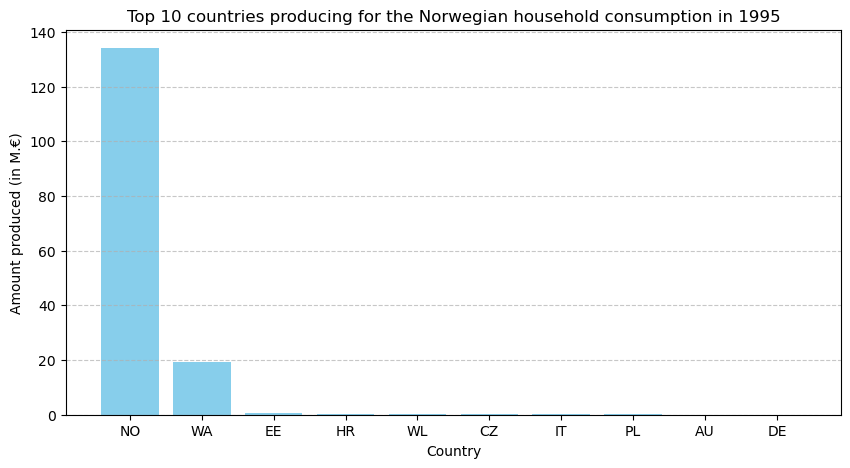

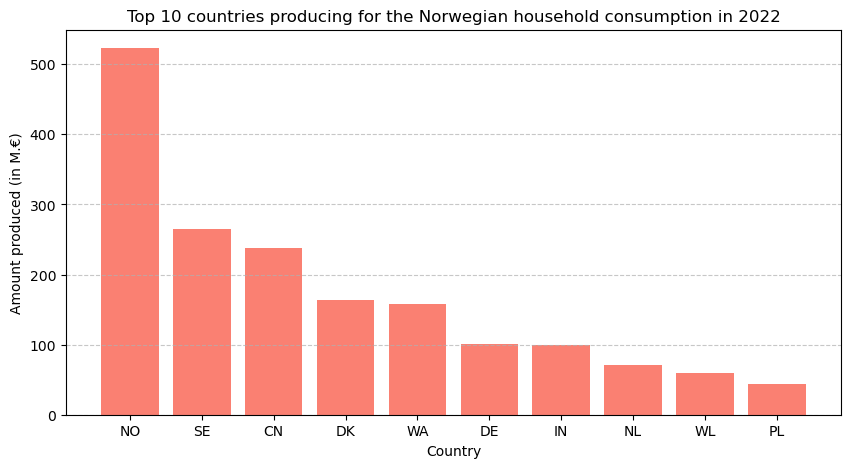

In [20]:
sorted_data_1995_Y = sorted_data_1995_Y.iloc[:10]  
sorted_data_2022_Y = sorted_data_2022_Y.iloc[:10] 

# plot the first histogram
plt.figure(figsize=(10, 5))
plt.bar(sorted_data_1995_Y.index.get_level_values(0), sorted_data_1995_Y, color='skyblue')
plt.title('Top 10 countries producing for the Norwegian household consumption in 1995')
plt.xlabel('Country')
plt.ylabel('Amount produced (in M.€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# plot the second histogram
plt.figure(figsize=(10, 5))
plt.bar(sorted_data_2022_Y.index.get_level_values(0), sorted_data_2022_Y, color='salmon')
plt.title('Top 10 countries producing for the Norwegian household consumption in 2022')
plt.xlabel('Country')
plt.ylabel('Amount produced (in M.€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

And let's store the data in our folder:

In [21]:
path_6 = path_file + '/data_processed/Part 1/top_10_countries_prod_Y_1995.xlsx'
path_7 = path_file + '/data_processed/Part 1/top_10_countries_prod_Y_2022.xlsx'

sorted_data_1995_Y.to_excel(path_6)
sorted_data_2022_Y.to_excel(path_7)

#### Evolution of the origin of Norwegian clothing consumption

Let's now have a look on the evolution of the percentages for the 10 biggest producers in Norway between 1990 and 2022.

Let's first identify the 10 biggest:


In [22]:
sum_production_country = pd.DataFrame(index = countries, columns= ['sum of clothing and textile consumed in Norway'])
sum_production_country = sum_production_country.fillna(0)
# Calculate the origin of the total of clothing and textile consummed in Norway for each year
for i in range(len(year)):
    YEAR = year[i]
    Y_yearic = exio_meta_dict[(str(YEAR), 'Y')].copy()
    yearly_data = Y_yearic.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')]
    sum_production_country['sum of clothing and textile consumed in Norway'] += yearly_data.groupby(level=0).sum()

sum_production_country = sum_production_country.sort_values(by='sum of clothing and textile consumed in Norway', ascending=False)
top_sum_production_country = sum_production_country.iloc[:10]


Now that we have the proportion of the 10 countries which produce the more for Norway, let's see how the numbers and the proportion evolved.

In [23]:
matrix_number_country = pd.DataFrame(index = year, columns= top_sum_production_country.index)
matrix_percentage_country = pd.DataFrame(index = year, columns= top_sum_production_country.index)
for i in range(len(year)):
    YEAR = year[i]
    Y_yearid = exio_meta_dict[(str(YEAR), 'Y')].copy()
    sum_yearly_data = Y_yearid.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].sum()
    # Calculate the number of clothing and textile consummed in Norway for each year
    for j in range(len(top_sum_production_country.index)):
        Y_yearie = exio_meta_dict[(str(YEAR), 'Y')].copy()
        country = top_sum_production_country.index[j]
        yearly_data = Y_yearie.loc[(country, 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')]
        matrix_number_country[country][YEAR] = yearly_data.sum()
        matrix_percentage_country[country][YEAR] = (yearly_data.sum() / sum_yearly_data) * 100    

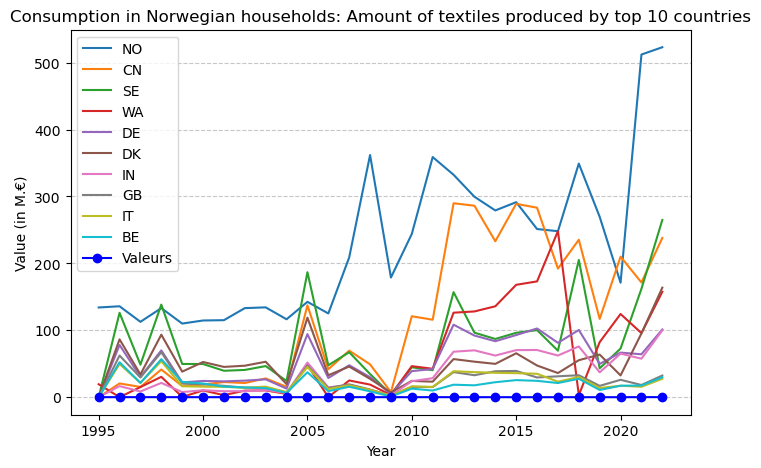

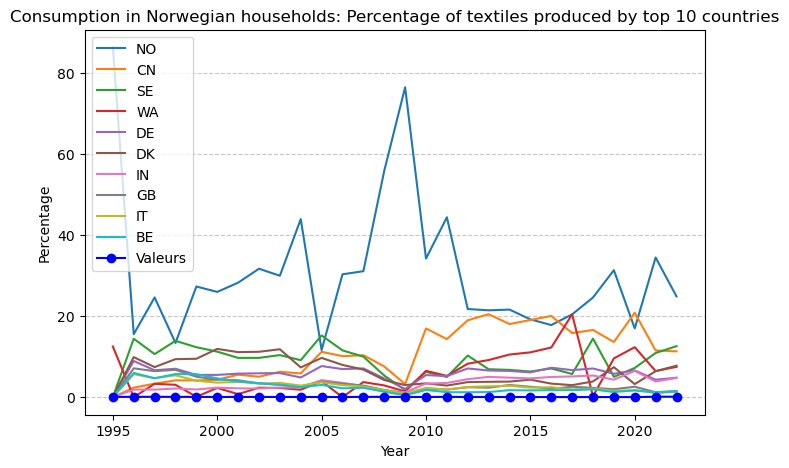

In [24]:
matrix_number_country.plot(figsize=(8, 5))
plt.plot(matrix_percentage.index, matrix_percentage['Percentage of clothing and textile produced in Norway'], marker='o', linestyle='-', color='b', label='Valeurs')
plt.title('Consumption in Norwegian households: Amount of textiles produced by top 10 countries')
plt.xlabel('Year')
plt.ylabel('Value (in M.€)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

matrix_percentage_country.plot(figsize=(8, 5))
plt.plot(matrix_percentage.index, matrix_percentage['Percentage of clothing and textile produced in Norway'], marker='o', linestyle='-', color='b', label='Valeurs')
plt.title('Consumption in Norwegian households: Percentage of textiles produced by top 10 countries')
plt.xlabel('Year')
plt.ylabel('Percentage')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

Let's export the data in our folder

In [25]:
path_8 = path_file + '/data_processed/Part 1/top_10_countries_prod_Y_percentage.xlsx'
path_9 = path_file + '/data_processed/Part 1/top_10_countries_prod_Y_amount.xlsx'

matrix_percentage_country.to_excel(path_8)
matrix_number_country.to_excel(path_9)

## Part 2: Top impact sectors for the Norwegian clothing system

After focusing on the apparel sector, we take a closer look at the environmental impact of Norway's textile industry.

### Calculation of the matrix

The first stage of this section involves calculating emission matrices for all years from 1995 to 2022. These calculations take a long time to perform, so they need to be stored in dictionary form for easy re-use.
For each year, we will calculate:
- the A and Leontief inverse
- the S matrix
- the M matrix
And then we will be able to use easily each matrix.

In [33]:
matrix_env_dict = {}

Let's now calculate each matrix. Because of calculation limitation, we will work with float32 instead of float64, but it can be changed by removing the command .astype(np.float32) for each row.

In [34]:
for i in range(len(year)):
    YEAR = year[i]
    print(YEAR)  # To follow the progress of the loop

    # Extraction of the data
    x_year = exio_meta_dict[(str(YEAR), 'x')].copy()
    Z_year = exio_meta_dict[(str(YEAR), 'Z')].copy().astype(np.float32)
    Y_year = exio_meta_dict[(str(YEAR), 'Y')].copy().astype(np.float32)
    F_year_airem = exio_meta_dict[(str(YEAR), 'F_airem')].copy().astype(np.float32)
    F_year_water = exio_meta_dict[(str(YEAR), 'F_water')].copy().astype(np.float32)

    if YEAR != 2022:
        F_year_land = exio_meta_dict[(str(YEAR), 'F_land')].copy().astype(np.float32)

    # Filter industries where indout = 0
    index_col = x_year[x_year['indout'] == 0].index.tolist()
    new_Z_year = Z_year.drop(index_col).drop(columns=index_col).copy().astype(np.float32)
    new_x_year = x_year.drop(index_col).copy()
    new_Y_year = Y_year.drop(index_col).copy().astype(np.float32)
    new_F_year_airem = F_year_airem.drop(columns=index_col).copy().astype(np.float32)
    new_F_year_water = F_year_water.drop(columns=index_col).copy().astype(np.float32)
    if YEAR != 2022:
        new_F_year_land = F_year_land.drop(columns=index_col).copy().astype(np.float32)

    # Build inverse of diagonal matrix as float32
    diag_raw = new_x_year['indout'].to_numpy(dtype=np.float32)
    diag_inv_matrix = np.diag(np.where(diag_raw != 0, 1.0 / diag_raw, 0.0)).astype(np.float32)

    # Matrices A and L
    A_year = new_Z_year.to_numpy(dtype=np.float32) @ diag_inv_matrix
    A_year = pd.DataFrame(A_year, index=new_Z_year.index, columns=new_Z_year.columns, dtype=np.float32)
    L_year = np.linalg.inv(np.eye(len(A_year), dtype=np.float32) - A_year.to_numpy(dtype=np.float32)).astype(np.float32)

    # Matrices S and M
    S_year_airem = new_F_year_airem.to_numpy(dtype=np.float32) @ diag_inv_matrix
    S_year_water = new_F_year_water.to_numpy(dtype=np.float32) @ diag_inv_matrix
    if YEAR != 2022:
        S_year_land = new_F_year_land.to_numpy(dtype=np.float32) @ diag_inv_matrix

    M_year_airem = S_year_airem @ L_year
    M_year_water = S_year_water @ L_year
    if YEAR != 2022:
        M_year_land = S_year_land @ L_year

    # Store the data
    matrix_env_dict[(str(YEAR), 'Z')] = new_Z_year
    matrix_env_dict[(str(YEAR), 'Y')] = new_Y_year
    matrix_env_dict[(str(YEAR), 'x')] = new_x_year
    matrix_env_dict[(str(YEAR), 'F_airem')] = new_F_year_airem
    matrix_env_dict[(str(YEAR), 'F_water')] = new_F_year_water
    if YEAR != 2022:
        matrix_env_dict[(str(YEAR), 'F_land')] = new_F_year_land
    matrix_env_dict[(str(YEAR), 'A')] = A_year
    matrix_env_dict[(str(YEAR), 'L')] = L_year
    matrix_env_dict[(str(YEAR), 'S_airem')] = S_year_airem
    matrix_env_dict[(str(YEAR), 'S_water')] = S_year_water
    if YEAR != 2022:
        matrix_env_dict[(str(YEAR), 'S_land')] = S_year_land
    matrix_env_dict[(str(YEAR), 'M_airem')] = M_year_airem
    matrix_env_dict[(str(YEAR), 'M_water')] = M_year_water
    if YEAR != 2022:
        matrix_env_dict[(str(YEAR), 'M_land')] = M_year_land


1995
1996
1997
1998
1999
2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022


We can now use these matrices to obtain the curves we're interested in.

### Evolution of the production volume required per unit output from the clothig industry.

As usual, let's first calculate in 1995 and in 2022:

From the Leontief inverse, we can have a look on the production volume required per unit output from the clothing industry.

In [35]:
L_1995 = matrix_env_dict[('1995', 'L')].copy()
L_2022 = matrix_env_dict[('2022', 'L')].copy()
new_Z_1995 = matrix_env_dict[('1995', 'Z')].copy()
new_Z_2022 = matrix_env_dict[('2022', 'Z')].copy()
L_1995_pd=pd.DataFrame(L_1995, index=new_Z_1995.index, columns=new_Z_1995.columns)

L_2022_pd=pd.DataFrame(L_2022, index=new_Z_2022.index, columns=new_Z_2022.columns)


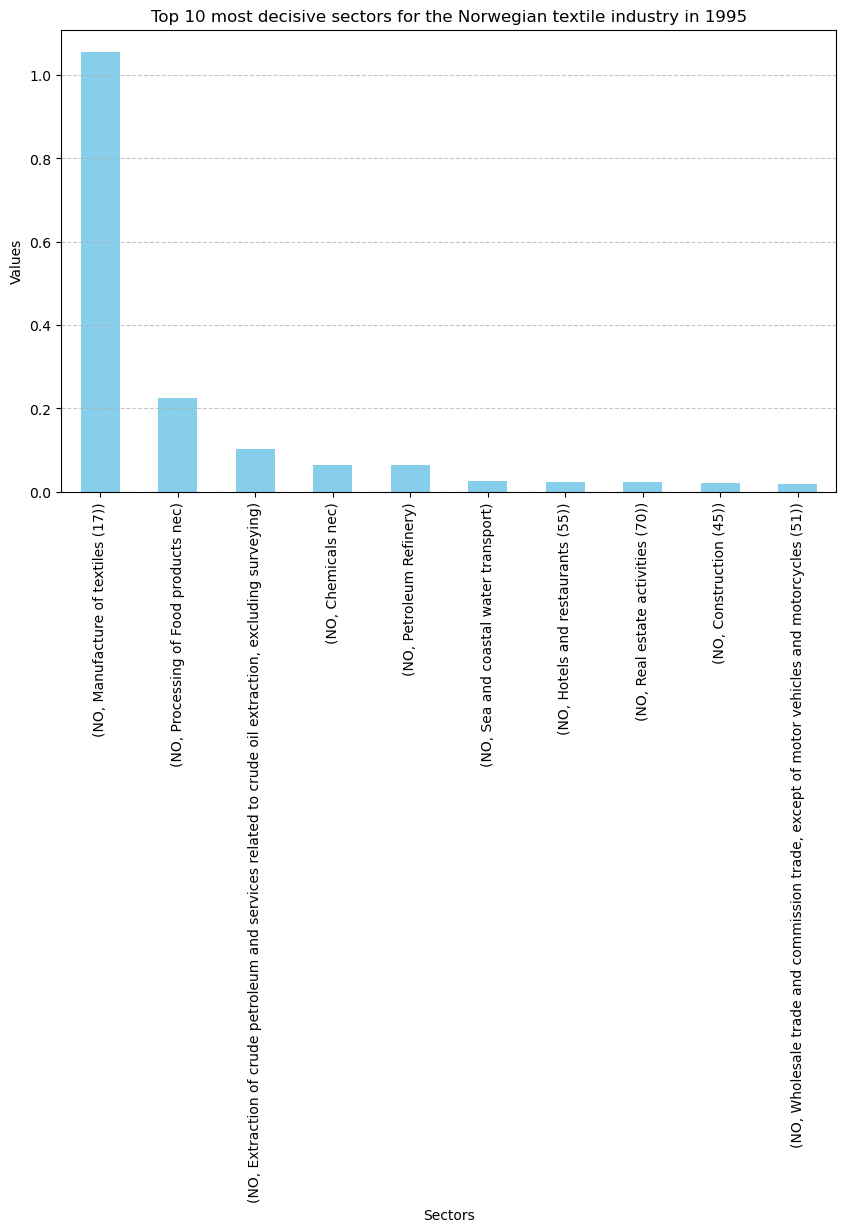

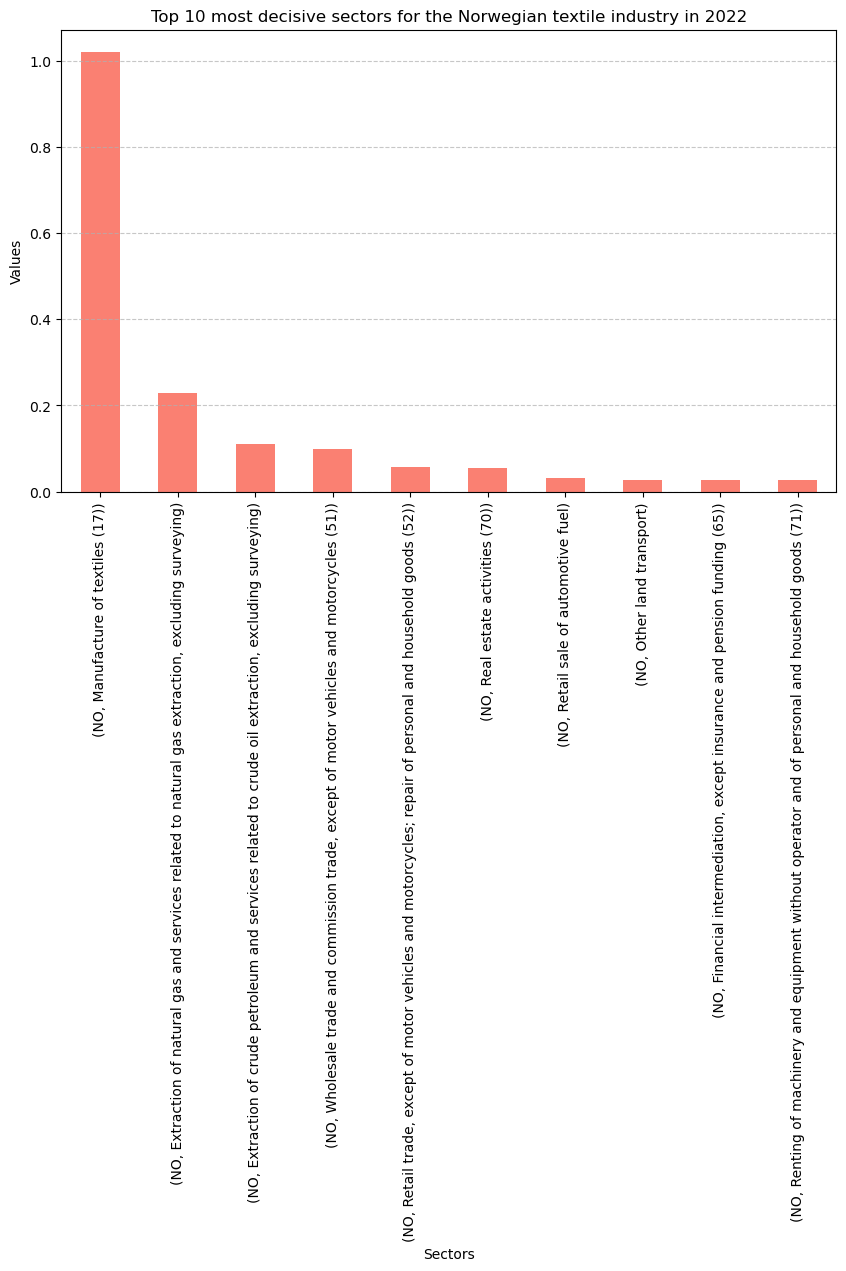

In [36]:
top_10_1995 = L_1995_pd.loc[:,('NO', 'Manufacture of textiles (17)')].nlargest(10)

# Print an histogram
plt.figure(figsize=(10, 6))
top_10_1995.plot(kind='bar', color='skyblue')
plt.title('Top 10 most decisive sectors for the Norwegian textile industry in 1995')
plt.xlabel('Sectors')
plt.ylabel('Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

top_10_2022 = L_2022_pd.loc[:,('NO', 'Manufacture of textiles (17)')].nlargest(10)
# Print an histogram
plt.figure(figsize=(10, 6))
top_10_2022.plot(kind='bar', color='salmon')
plt.title('Top 10 most decisive sectors for the Norwegian textile industry in 2022')
plt.xlabel('Sectors')
plt.ylabel('Values')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


Let's now export our data:

In [37]:
path_10 = path_file + '/data_processed/Part 2/top_10_dec_sect1995.xlsx'
path_11 = path_file + '/data_processed/Part 2/top_10_dec_sect2022.xlsx'

top_10_1995.to_excel(path_10)
top_10_2022.to_excel(path_11)

### Impact Categories

Let's now focus on the three impact categories we're interested about:

Let's calculate the footprint and the direct emissions by industry and by country that are caused by household consumption of the textile industry in Norway for the three impact categories: air emissions, water impact and land use.

#### Direct impacts

In [48]:
new_Z_2021 = matrix_env_dict[('2021', 'Z')].copy()

new_Y_1995 = matrix_env_dict[('1995', 'Y')].copy()
new_Y_2021 = matrix_env_dict[('2021', 'Y')].copy()
new_Y_2022 = matrix_env_dict[('2022', 'Y')].copy()

y_clothes_1995=np.zeros(len(new_Z_1995))
y_clothes_2021=np.zeros(len(new_Z_2021))
y_clothes_2022=np.zeros(len(new_Z_2022))

index_clothing_1995 = new_Y_1995.index.get_level_values(1) == 'Manufacture of textiles (17)'
index_clothing_2021 = new_Y_2021.index.get_level_values(1) == 'Manufacture of textiles (17)'
index_clothing_2022 = new_Y_2022.index.get_level_values(1) == 'Manufacture of textiles (17)'

y_clothes_1995[index_clothing_1995] = new_Y_1995.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()
y_clothes_2021[index_clothing_2021] = new_Y_2021.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()
y_clothes_2022[index_clothing_2022] = new_Y_2022.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()

In [51]:
L_2021 = matrix_env_dict[('2021', 'L')].copy()


S_1995_airem = matrix_env_dict[('1995', 'S_airem')].copy()
S_2022_airem = matrix_env_dict[('2022', 'S_airem')].copy()
S_1995_water = matrix_env_dict[('1995', 'S_water')].copy()
S_2022_water = matrix_env_dict[('2022', 'S_water')].copy()
S_1995_land = matrix_env_dict[('1995', 'S_land')].copy()
S_2021_land = matrix_env_dict[('2021', 'S_land')].copy()

index_col_S_airem_1995 = exio_meta_dict[('1995', 'F_airem')].index.tolist()
index_col_S_airem_2022 = exio_meta_dict[('2022', 'F_airem')].index.tolist()
index_col_S_water_1995 = exio_meta_dict[('1995', 'F_water')].index.tolist()
index_col_S_water_2022 = exio_meta_dict[('2022', 'F_water')].index.tolist()
index_col_S_land_1995 = exio_meta_dict[('1995', 'F_land')].index.tolist()
index_col_S_land_2021 = exio_meta_dict[('2021', 'F_land')].index.tolist()

S_1995_airem = pd.DataFrame(S_1995_airem, index=index_col_S_airem_1995, columns=new_Z_1995.columns)
S_2022_airem = pd.DataFrame(S_2022_airem, index=index_col_S_airem_2022, columns=new_Z_2022.columns)
S_1995_water = pd.DataFrame(S_1995_water, index=index_col_S_water_1995, columns=new_Z_1995.columns)
S_2022_water = pd.DataFrame(S_2022_water, index=index_col_S_water_2022, columns=new_Z_2022.columns)
S_1995_water_filtred = S_1995_water[S_1995_water.index.str.startswith('Water Consumption')].sum(axis=0)
S_2022_water_filtred = S_2022_water[S_2022_water.index.str.startswith('Water Consumption')].sum(axis=0)
S_1995_land = pd.DataFrame(S_1995_land, index=index_col_S_land_1995, columns=new_Z_1995.columns)
S_2021_land = pd.DataFrame(S_2021_land, index=index_col_S_land_2021, columns=new_Z_2021.columns)

# Calculate the delta for the top 10 sectors in 1995 and 2022 for airem

Delta_clothes_airem_1995 = np.diag(S_1995_airem.loc['CO2 - combustion - air',:]) @ L_1995 @ y_clothes_1995 * 1e-9
Delta_clothes_airem_1995_pd = pd.DataFrame(data=Delta_clothes_airem_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

Delta_clothes_airem_2022 = np.diag(S_2022_airem.loc['CO2 - combustion - air',:]) @ L_2022 @ y_clothes_2022 * 1e-9
Delta_clothes_airem_2022_pd = pd.DataFrame(data=Delta_clothes_airem_2022, columns = ['Manufacture of textiles (17)'], index=new_Z_2022.index)

top_10_delta_clothes_airem_1995 = Delta_clothes_airem_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_delta_clothes_airem_2022 = Delta_clothes_airem_2022_pd.nlargest(10, 'Manufacture of textiles (17)')

# Calculate the delta for the top 10 sectors in 1995 and 2022 for water
Delta_clothes_water_1995 = np.diag(S_1995_water_filtred) @ L_1995 @ y_clothes_1995
Delta_clothes_water_1995_pd = pd.DataFrame(data=Delta_clothes_water_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

Delta_clothes_water_2022 = np.diag(S_2022_water_filtred) @ L_2022 @ y_clothes_2022
Delta_clothes_water_2022_pd = pd.DataFrame(data=Delta_clothes_water_2022, columns = ['Manufacture of textiles (17)'], index=new_Z_2022.index)

top_10_delta_clothes_water_1995 = Delta_clothes_water_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_delta_clothes_water_2022 = Delta_clothes_water_2022_pd.nlargest(10, 'Manufacture of textiles (17)')

# Calculate the delta for the top 10 sectors in 1995 and 2021 for land
Delta_clothes_land_1995 = np.diag(S_1995_land.sum(axis=0)) @ L_1995 @ y_clothes_1995
Delta_clothes_land_1995_pd = pd.DataFrame(data=Delta_clothes_land_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

Delta_clothes_land_2021 = np.diag(S_2021_land.sum(axis=0)) @ L_2021 @ y_clothes_2021
Delta_clothes_land_2021_pd = pd.DataFrame(data=Delta_clothes_land_2021, columns = ['Manufacture of textiles (17)'], index=new_Z_2021.index)

top_10_delta_clothes_land_1995 = Delta_clothes_land_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_delta_clothes_land_2021 = Delta_clothes_land_2021_pd.nlargest(10, 'Manufacture of textiles (17)')




Let's plot the graphs for the 3 impact categories:

Text(0.5, 0, 'Megatons of CO$_2$')

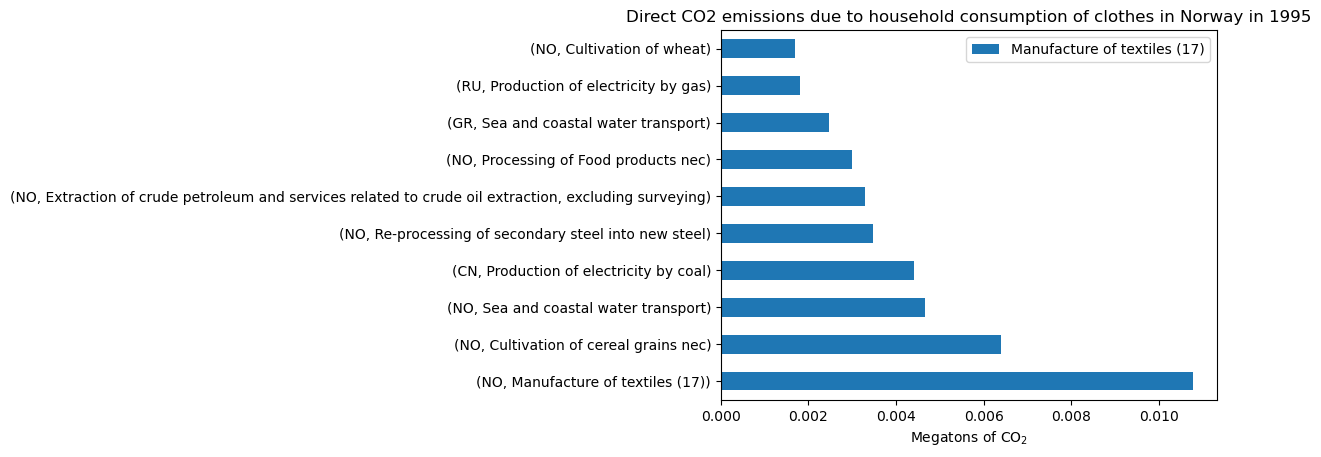

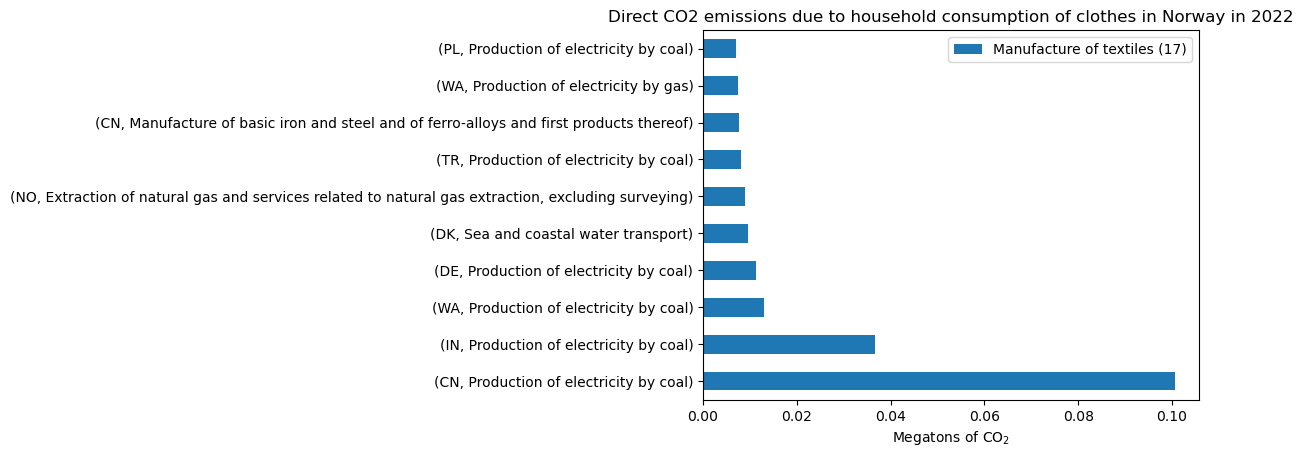

In [52]:
ax_1995 = top_10_delta_clothes_airem_1995.plot(kind='barh', title = 'Direct CO2 emissions due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('Megatons of CO$_2$')

ax_2022 = top_10_delta_clothes_airem_2022.plot(kind='barh', title = 'Direct CO2 emissions due to household consumption of clothes in Norway in 2022')
ax_2022.set_xlabel('Megatons of CO$_2$')


Text(0.5, 0, 'Mm3')

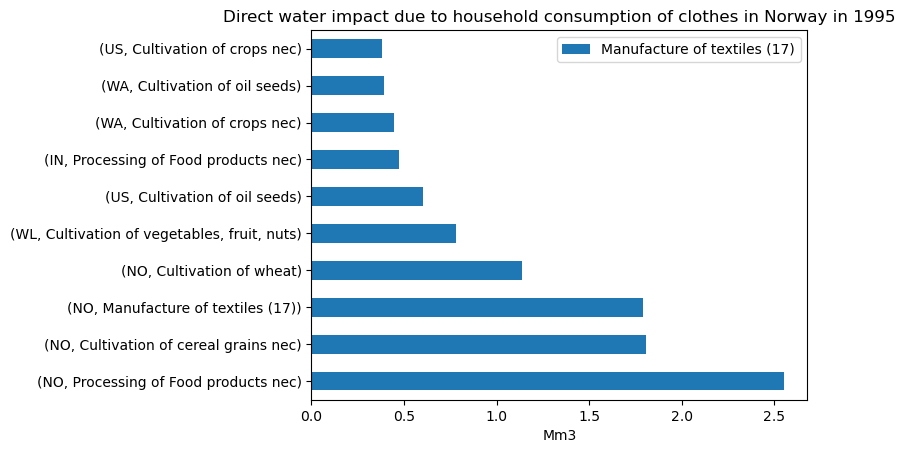

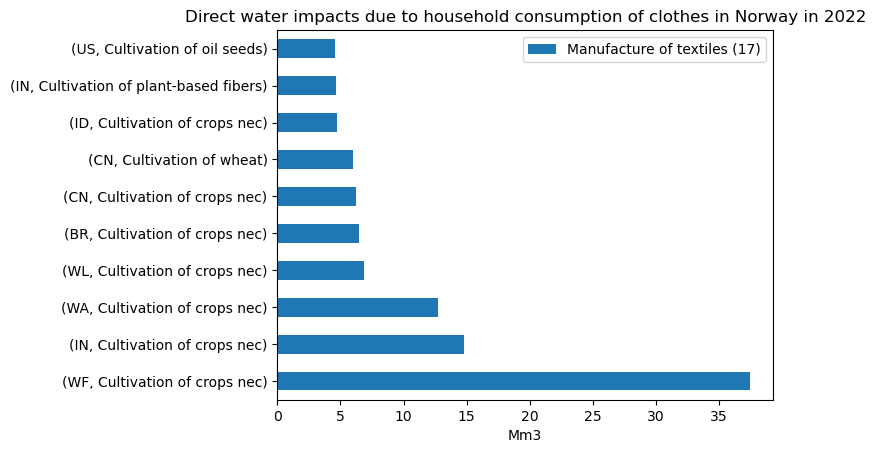

In [53]:
ax_1995 = top_10_delta_clothes_water_1995.plot(kind='barh', title = 'Direct water impact due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('Mm3')

ax_2022 = top_10_delta_clothes_water_2022.plot(kind='barh', title = 'Direct water impacts due to household consumption of clothes in Norway in 2022')
ax_2022.set_xlabel('Mm3')

Text(0.5, 0, 'km2')

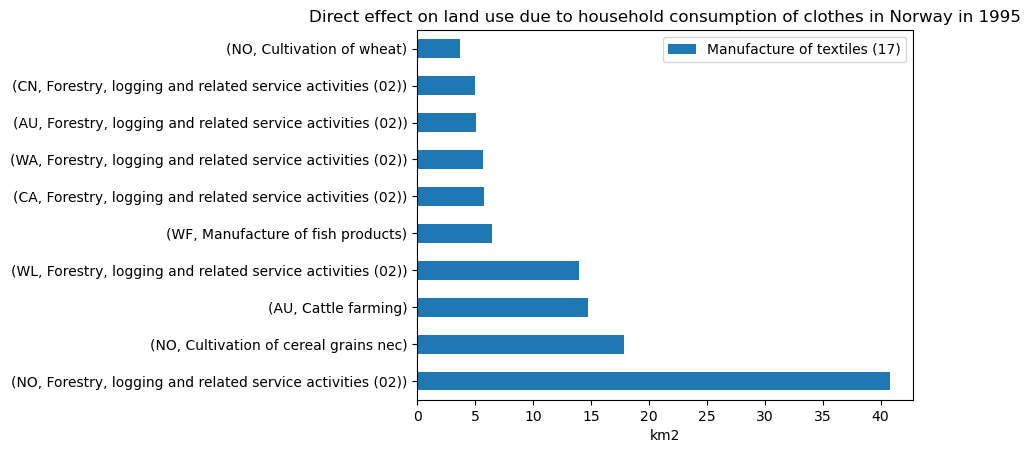

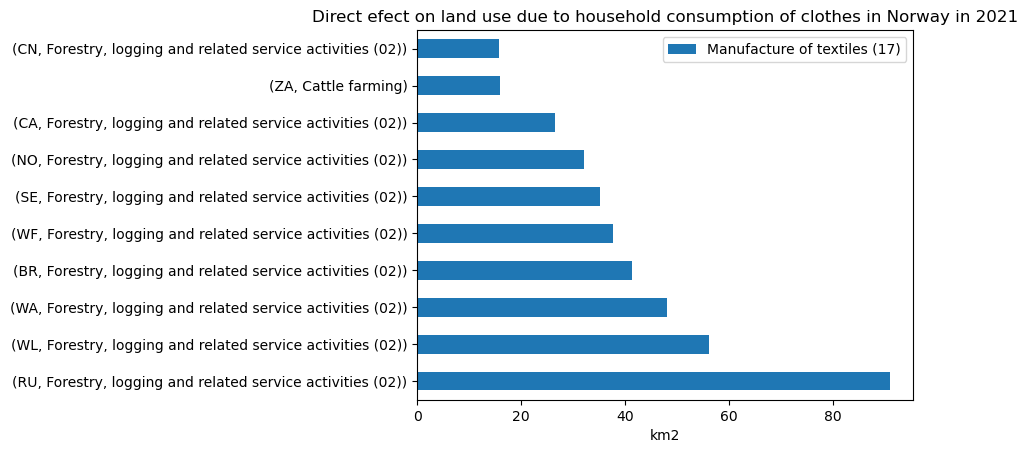

In [54]:
ax_1995 = top_10_delta_clothes_land_1995.plot(kind='barh', title = 'Direct effect on land use due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('km2')

ax_2022 = top_10_delta_clothes_land_2021.plot(kind='barh', title = 'Direct efect on land use due to household consumption of clothes in Norway in 2021')
ax_2022.set_xlabel('km2')

And we can now export our data

In [55]:
path_12 = path_file + '/data_processed/Part 2/top_10_delta_clothes_airem_1995.xlsx'
path_13 = path_file + '/data_processed/Part 2/top_10_delta_clothes_airem_2022.xlsx'
path_14 = path_file + '/data_processed/Part 2/top_10_delta_clothes_water_1995.xlsx'
path_15 = path_file + '/data_processed/Part 2/top_10_delta_clothes_water_2022.xlsx'
path_16 = path_file + '/data_processed/Part 2/top_10_delta_clothes_land_1995.xlsx'
path_17 = path_file + '/data_processed/Part 2/top_10_delta_clothes_land_2021.xlsx'

top_10_delta_clothes_airem_1995.to_excel(path_12)
top_10_delta_clothes_airem_2022.to_excel(path_13)
top_10_delta_clothes_water_1995.to_excel(path_14)
top_10_delta_clothes_water_2022.to_excel(path_15)
top_10_delta_clothes_land_1995.to_excel(path_16)
top_10_delta_clothes_land_2021.to_excel(path_17)

#### Footprint

Let's do the same for the carbon footprint:

In [57]:
#for airem
footprint_airem_1995 = S_1995_airem.loc['CO2 - combustion - air',:] @ L_1995 @ np.diag(y_clothes_1995) * 1e-9
footprint_airem_1995_pd = pd.DataFrame(data=footprint_airem_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

footprint_airem_2022 = S_2022_airem.loc['CO2 - combustion - air',:] @ L_2022 @ np.diag(y_clothes_2022) * 1e-9
footprint_airem_2022_pd = pd.DataFrame(data=footprint_airem_2022, columns = ['Manufacture of textiles (17)'], index=new_Z_2022.index)

top_10_footprint_airem_1995 = footprint_airem_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_footprint_airem_2022 = footprint_airem_2022_pd.nlargest(10, 'Manufacture of textiles (17)')

#for water
footprint_water_1995 = S_1995_water_filtred @ L_1995 @ np.diag(y_clothes_1995)
footprint_water_1995_pd = pd.DataFrame(data=footprint_water_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

footprint_water_2022 = S_2022_water_filtred @ L_2022 @ np.diag(y_clothes_2022)
footprint_water_2022_pd = pd.DataFrame(data=footprint_water_2022, columns = ['Manufacture of textiles (17)'], index=new_Z_2022.index)

top_10_footprint_water_1995 = footprint_water_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_footprint_water_2022 = footprint_water_2022_pd.nlargest(10, 'Manufacture of textiles (17)')

#for land
footprint_land_1995 = S_1995_land.sum(axis=0) @ L_1995 @ np.diag(y_clothes_1995)
footprint_land_1995_pd = pd.DataFrame(data=footprint_land_1995, columns = ['Manufacture of textiles (17)'], index=new_Z_1995.index)

footprint_land_2021 = S_2021_land.sum(axis=0) @ L_2021 @ np.diag(y_clothes_2021)
footprint_land_2021_pd = pd.DataFrame(data=footprint_land_2021, columns = ['Manufacture of textiles (17)'], index=new_Z_2021.index)

top_10_footprint_land_1995 = footprint_land_1995_pd.nlargest(10, 'Manufacture of textiles (17)')
top_10_footprint_land_2021 = footprint_land_2021_pd.nlargest(10, 'Manufacture of textiles (17)')



Text(0.5, 0, 'Megatons of CO$_2$')

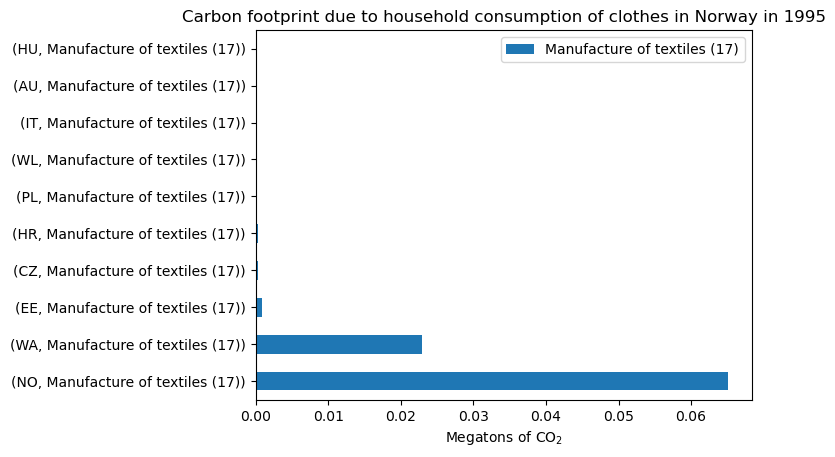

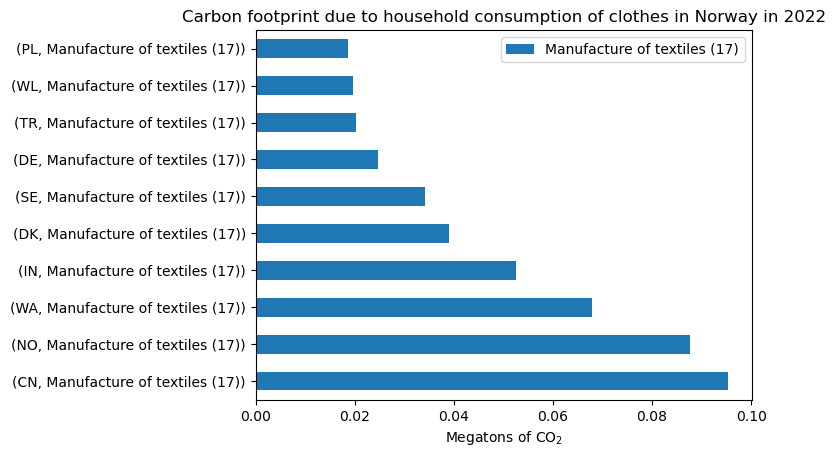

In [58]:
ax_1995 = top_10_footprint_airem_1995.plot(kind='barh', title = 'Carbon footprint due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('Megatons of CO$_2$')

ax_2022 = top_10_footprint_airem_2022.plot(kind='barh', title = 'Carbon footprint due to household consumption of clothes in Norway in 2022')
ax_2022.set_xlabel('Megatons of CO$_2$')

Text(0.5, 0, 'Mm3')

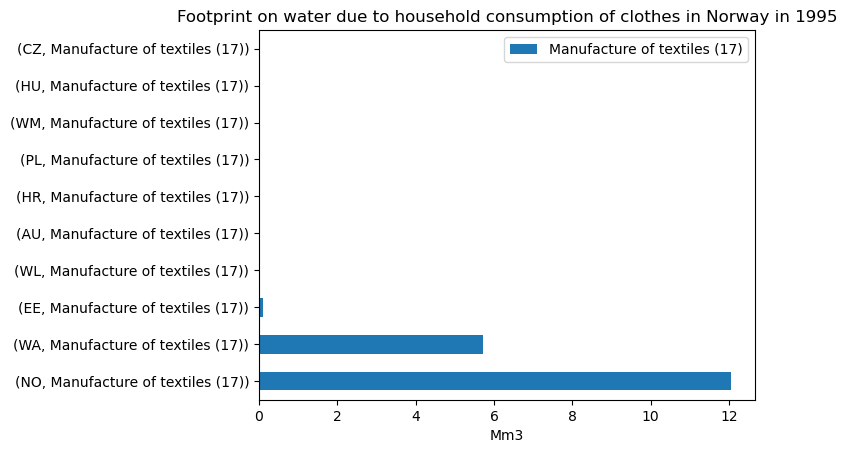

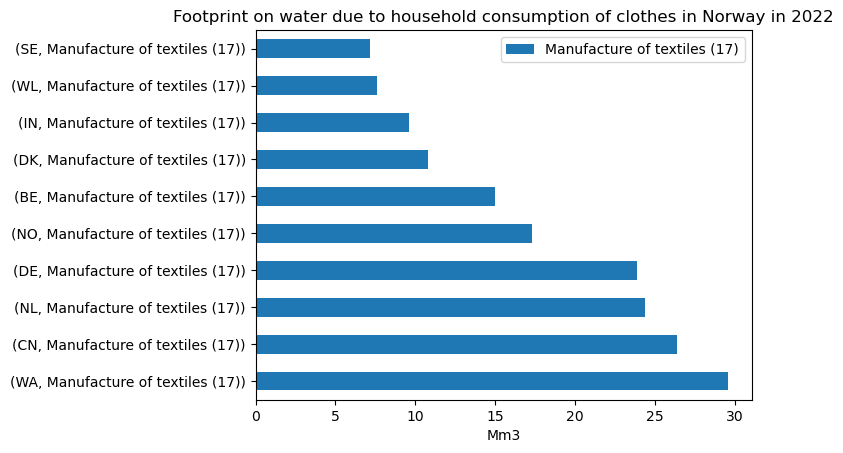

In [60]:
ax_1995 = top_10_footprint_water_1995.plot(kind='barh', title = 'Footprint on water due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('Mm3')

ax_2022 = top_10_footprint_water_2022.plot(kind='barh', title = 'Footprint on water due to household consumption of clothes in Norway in 2022')
ax_2022.set_xlabel('Mm3')

Text(0.5, 0, 'km2')

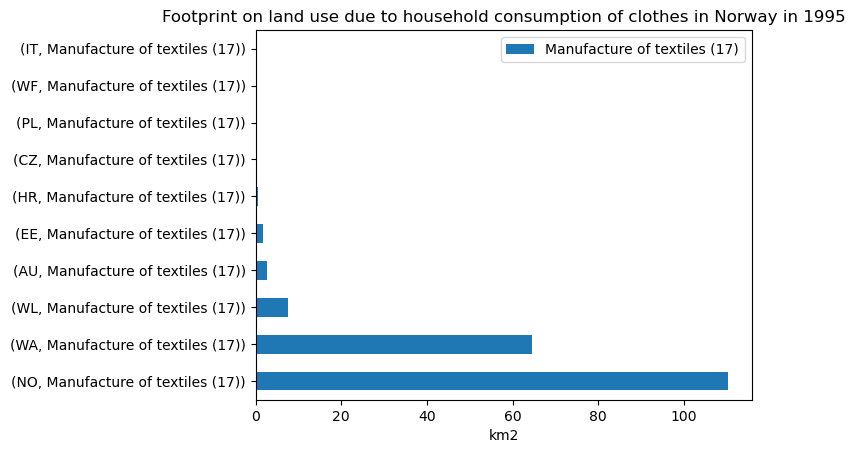

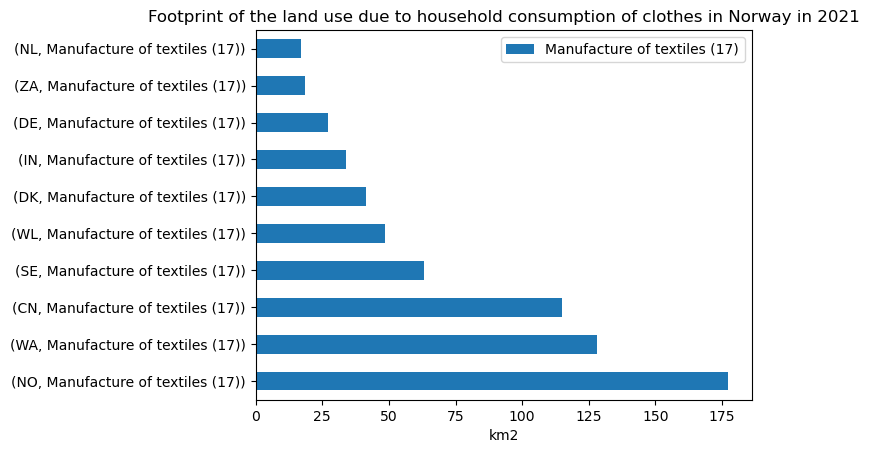

In [59]:
ax_1995 = top_10_footprint_land_1995.plot(kind='barh', title = 'Footprint on land use due to household consumption of clothes in Norway in 1995')
ax_1995.set_xlabel('km2')

ax_2022 = top_10_footprint_land_2021.plot(kind='barh', title = 'Footprint of the land use due to household consumption of clothes in Norway in 2021')
ax_2022.set_xlabel('km2')

And now we export the data:

In [61]:
path_18 = path_file + '/data_processed/Part 2/top_10_footprint_airem_1995.xlsx'
path_19 = path_file + '/data_processed/Part 2/top_10_footprint_airem_2022.xlsx'
path_20 = path_file + '/data_processed/Part 2/top_10_footprint_water_1995.xlsx'
path_21 = path_file + '/data_processed/Part 2/top_10_footprint_water_2022.xlsx'
path_22 = path_file + '/data_processed/Part 2/top_10_footprint_land_1995.xlsx'
path_23 = path_file + '/data_processed/Part 2/top_10_footprint_land_2021.xlsx'

top_10_footprint_airem_1995.to_excel(path_18)
top_10_footprint_airem_2022.to_excel(path_19)
top_10_footprint_water_1995.to_excel(path_20)
top_10_footprint_water_2022.to_excel(path_21)
top_10_footprint_land_1995.to_excel(path_22)
top_10_footprint_land_2021.to_excel(path_23)

We can see a certain logic in this figure if we compare with the graph of the total producers of clothing for Norway. We can also conclude that producing in China is moreCO2-emitting than producing in Norway.

## Part 3: Evolution of clothing on the 3 impact categories

Another relevant point to consider is the evolution of the environmental impact of the clothing system in Norway over the years.

For each year, we will calculate the total impact related to the consumption of clothing by the households in Norway.

### Environmental impact in Norway

In [73]:
environmental_impact_pd = pd.DataFrame(index=year, columns=['Air emissions (Mt CO2)', 'Water consumption (Mm3)', 'Land use (km2)'])

for i in range(len(year)):
    YEAR = year[i]
    print(YEAR)  # To follow the progress of the loop
    try:
        # Extraction of the data
        x_year = exio_meta_dict[(str(YEAR),'x')].copy()
        Y_year = exio_meta_dict[(str(YEAR),'Y')].copy()
        index_col = x_year[x_year['indout'] == 0].index.tolist()
        new_Y_year = Y_year.drop(index_col).copy()
        y_clothes_year = np.zeros(len(new_Y_year))
        index_clothing_year = new_Y_year.index.get_level_values(1) == 'Manufacture of textiles (17)'
        y_clothes_year[index_clothing_year] = new_Y_year.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()
        L_year = matrix_env_dict[(str(YEAR), 'L')].copy()
        
        S_year_airem_data = matrix_env_dict[(str(YEAR), 'S_airem')].copy()
        S_year_water_data = matrix_env_dict[(str(YEAR), 'S_water')].copy()
        S_year_landuse_data = matrix_env_dict[(str(YEAR), 'S_land')].copy()

        index_col_S_airem_year = exio_meta_dict[(str(YEAR), 'F_airem')].index.tolist()
        index_col_S_water_year = exio_meta_dict[(str(YEAR), 'F_water')].index.tolist()
        index_col_S_landuse_year = exio_meta_dict[(str(YEAR), 'F_land')].index.tolist()

        S_year_airem = pd.DataFrame(S_year_airem_data, index=index_col_S_airem_year, columns=new_Y_year.index)
        S_year_water = pd.DataFrame(S_year_water_data, index=index_col_S_water_year, columns=new_Y_year.index)
        S_year_landuse = pd.DataFrame(S_year_landuse_data, index=index_col_S_landuse_year, columns=new_Y_year.index)

        S_year_airem_filtred = S_year_airem[S_year_airem.index.str.startswith('CO2 - combustion - air')].sum(axis=0)
        S_year_water_filtred = S_year_water[S_year_water.index.str.startswith('Water Consumption')].sum(axis=0)
        S_year_landuse_filtred = S_year_landuse.sum(axis=0)


            # We calculate the environmental impacts
        Delta_clothes_year_airem = S_year_airem_filtred @ L_year @ y_clothes_year * 1e-9
        Delta_clothes_year_water = S_year_water_filtred @ L_year @ y_clothes_year
        Delta_clothes_year_landuse = S_year_landuse_filtred @ L_year @ y_clothes_year

            # Final dataframe
        environmental_impact_pd.loc[YEAR, 'Air emissions (Mt CO2)'] = Delta_clothes_year_airem.sum()
        environmental_impact_pd.loc[YEAR, 'Water consumption (Mm3)'] = Delta_clothes_year_water.sum()
        environmental_impact_pd.loc[YEAR, 'Land use (km2)'] = Delta_clothes_year_landuse.sum()

    except Exception as e:
        print(f"Année {YEAR} ignorée : {e}")

1995
1996
1997
1998
1999
2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020
2021
2022
Année 2022 ignorée : ('2022', 'S_land')


In [74]:
environmental_impact_pd = environmental_impact_pd.dropna()

Let's now plot a graph with the evolution of the three columns over the years:

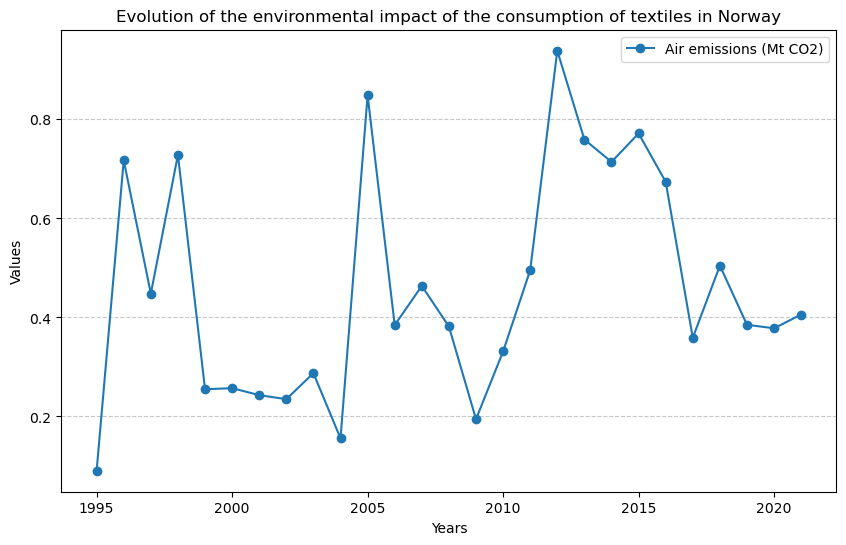

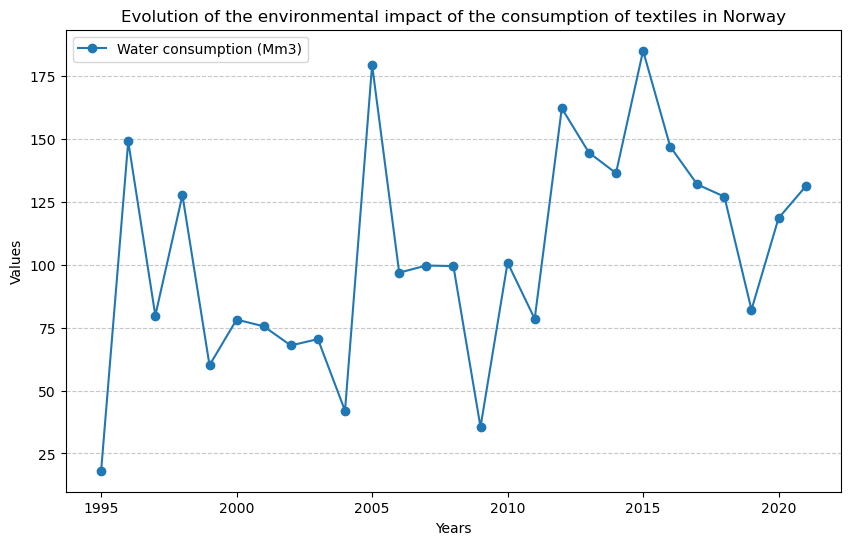

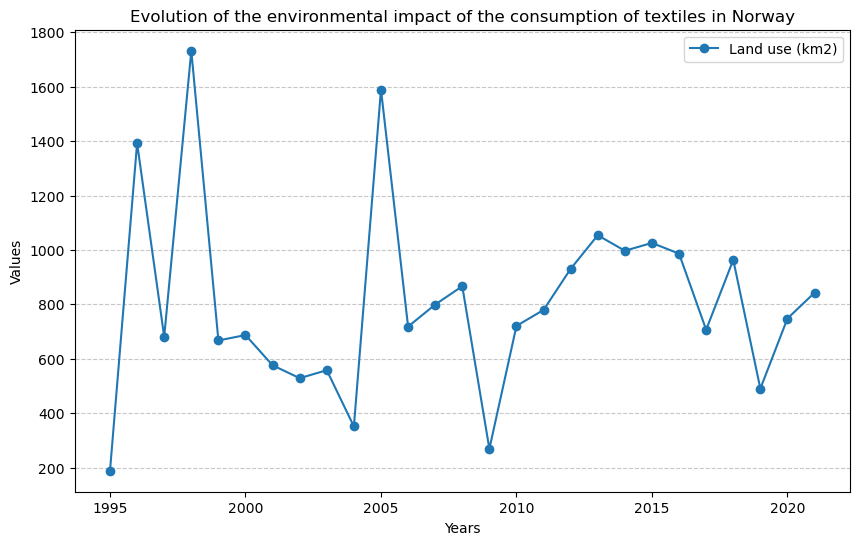

In [75]:
plt.figure(figsize=(10, 6))
plt.plot(environmental_impact_pd.index, environmental_impact_pd['Air emissions (Mt CO2)'], marker='o', label='Air emissions (Mt CO2)')


plt.title("Evolution of the environmental impact of the consumption of textiles in Norway")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(environmental_impact_pd.index, environmental_impact_pd['Water consumption (Mm3)'], marker='o', label='Water consumption (Mm3)')


plt.title("Evolution of the environmental impact of the consumption of textiles in Norway")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(environmental_impact_pd.index, environmental_impact_pd['Land use (km2)'], marker='o', label='Land use (km2)')


plt.title("Evolution of the environmental impact of the consumption of textiles in Norway")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

And finally we can export our data:

In [76]:
path_24 = path_file + '/data_processed/Part 3/total_environmental_impact.xlsx'
environmental_impact_pd.to_excel(path_24)



To have a better view of the evolutions of each columns, let's normalize each column:

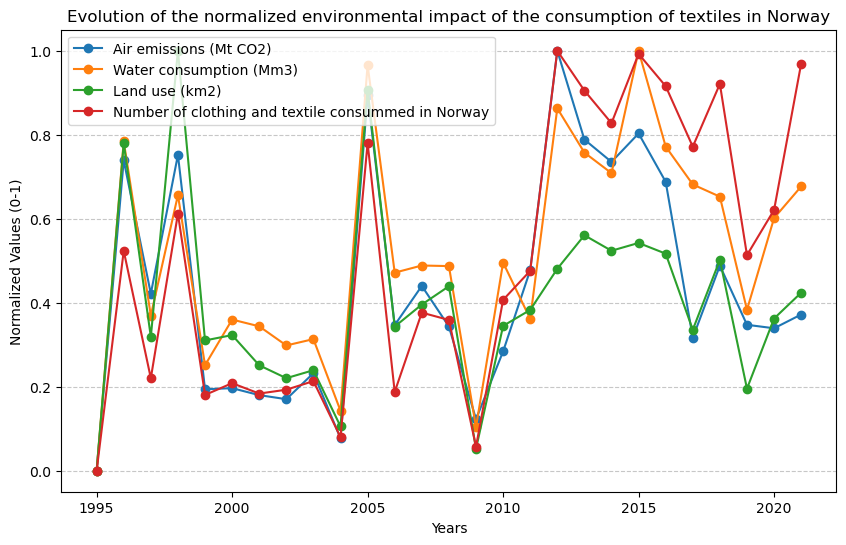

In [77]:
environmental_impact_pd['Number of clothing and textile consummed in Norway'] = matrix_number_clothes_consumed["Number of clothing and textile consummed in Norway"]

scaler = MinMaxScaler()
environmental_impact_normalized = pd.DataFrame(
    scaler.fit_transform(environmental_impact_pd),
    index=environmental_impact_pd.index,
    columns=environmental_impact_pd.columns
)


plt.figure(figsize=(10, 6))
for column in environmental_impact_normalized.columns:
    plt.plot(environmental_impact_normalized.index, environmental_impact_normalized[column], marker='o', label=column)



plt.title("Evolution of the normalized environmental impact of the consumption of textiles in Norway")
plt.xlabel("Years")
plt.ylabel("Normalized Values (0-1)")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We also export the data:

In [78]:
path_25 = path_file + '/data_processed/Part 3/normalized_environmental_impact.xlsx'
environmental_impact_normalized.to_excel(path_25)

### Comparison between the Norwegian CO2 emissions embodied into domestic production vs import

Another point that could be interested to focus on is the difference between the CO2 emitted by Norway for their own consumption vs the CO2 emissions produced by other countries for Norwegian clothing system.

Let's first calculate the CO2 emissions for the domestic production over the years:

In [82]:
prod_co2_pd = pd.DataFrame(index=year, columns=['Domestic production CO2 emissions (Mt CO2)'])
for i in range(len(year)):
    YEAR = year[i]
    try:
        # Extraction of the data
        x_year = exio_meta_dict[(str(YEAR),'x')].copy()
        Y_year = exio_meta_dict[(str(YEAR),'Y')].copy()
        index_col = x_year[x_year['indout'] == 0].index.tolist()
        new_Y_year = Y_year.drop(index_col).copy()
        y_clothes_year = np.zeros(len(new_Y_year))
        index_clothing_year = new_Y_year.index.get_level_values(1) == 'Manufacture of textiles (17)'
        y_clothes_year[index_clothing_year] = new_Y_year.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()
        L_year = matrix_env_dict[(str(YEAR), 'L')].copy()
        
        S_year_airem_data = matrix_env_dict[(str(YEAR), 'S_airem')].copy()
        S_year_water_data = matrix_env_dict[(str(YEAR), 'S_water')].copy()
        S_year_landuse_data = matrix_env_dict[(str(YEAR), 'S_land')].copy()

        index_col_S_airem_year = exio_meta_dict[(str(YEAR), 'F_airem')].index.tolist()
        index_col_S_water_year = exio_meta_dict[(str(YEAR), 'F_water')].index.tolist()
        index_col_S_landuse_year = exio_meta_dict[(str(YEAR), 'F_land')].index.tolist()

        S_year_airem = pd.DataFrame(S_year_airem_data, index=index_col_S_airem_year, columns=new_Y_year.index)
        S_year_water = pd.DataFrame(S_year_water_data, index=index_col_S_water_year, columns=new_Y_year.index)
        S_year_landuse = pd.DataFrame(S_year_landuse_data, index=index_col_S_landuse_year, columns=new_Y_year.index)

        S_year_airem_filtred = S_year_airem[S_year_airem.index.str.startswith('CO2 - combustion - air')].sum(axis=0)
        S_year_water_filtred = S_year_water[S_year_water.index.str.startswith('Water Consumption')].sum(axis=0)
        S_year_landuse_filtred = S_year_landuse.sum(axis=0)
        
        # We create our y vector
        y_clothes_year = np.zeros(len(new_Y_year),)
        index_to_find = ('NO', 'Manufacture of textiles (17)')
        if index_to_find in new_Y_year.index:
            index_clothing_year = new_Y_year.index.get_loc(index_to_find)
            col_to_use = ('NO', 'Final consumption expenditure by households')

            if col_to_use in new_Y_year.columns:
                y_clothes_year[index_clothing_year] = new_Y_year.loc[index_to_find, col_to_use]
            else:
                raise KeyError(f"Colonne {col_to_use} absente")
        else:
            raise KeyError(f"Secteur {index_to_find} absent")

        # we calculate the environmental impacts
        Delta_clothes_year_airem = S_year_airem_filtred @ L_year @ y_clothes_year * 1e-9
        Delta_clothes_year_water = S_year_water_filtred @ L_year @ y_clothes_year
        Delta_clothes_year_landuse = S_year_landuse_filtred @ L_year @ y_clothes_year

        # Final dataframe
        prod_co2_pd.loc[YEAR, 'Domestic production CO2 emissions (Mt CO2)'] = Delta_clothes_year_airem.sum()
        prod_co2_pd.loc[YEAR, 'Domestic production water consumption (Mm3)'] = Delta_clothes_year_water.sum()
        prod_co2_pd.loc[YEAR, 'Domestic production land use (km2)'] = Delta_clothes_year_landuse.sum()
    except Exception as e:
        print(f"Année {YEAR} ignorée : {e}")

Année 2022 ignorée : ('2022', 'S_land')


To find the graph for all the countries except Norway, we will just substract the two columns we have.

In [83]:
prod_co2_pd['CO2 emissions due to importations (Mt CO2)'] = environmental_impact_pd['Air emissions (Mt CO2)'] - prod_co2_pd['Domestic production CO2 emissions (Mt CO2)']
prod_co2_pd['Water consumption due to importations (Mm3)'] = environmental_impact_pd['Water consumption (Mm3)'] - prod_co2_pd['Domestic production water consumption (Mm3)']
prod_co2_pd['Land use due to importations (km2)'] = environmental_impact_pd['Land use (km2)'] - prod_co2_pd['Domestic production land use (km2)']

#### Plot of CO2 total emissions

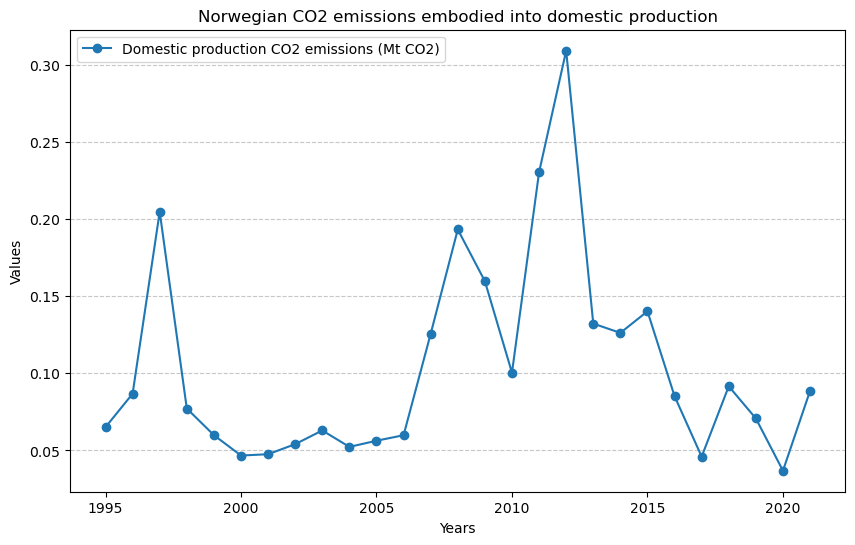

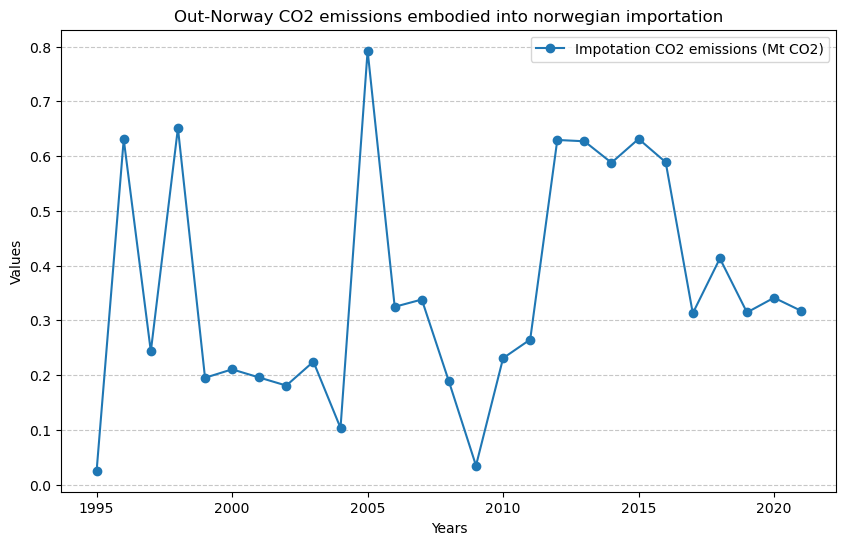

In [81]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production CO2 emissions (Mt CO2)'], marker='o', label='Domestic production CO2 emissions (Mt CO2)')
plt.title("Norwegian CO2 emissions embodied into domestic production")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['CO2 emissions due to importations (Mt CO2)'], marker='o', label='Impotation CO2 emissions (Mt CO2)')
plt.title("Out-Norway CO2 emissions embodied into norwegian importation")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We export the data:

In [85]:
path_26 = path_file + '/data_processed/Part 3/tot_co2_impact.xlsx'
prod_co2_pd.to_excel(path_26)

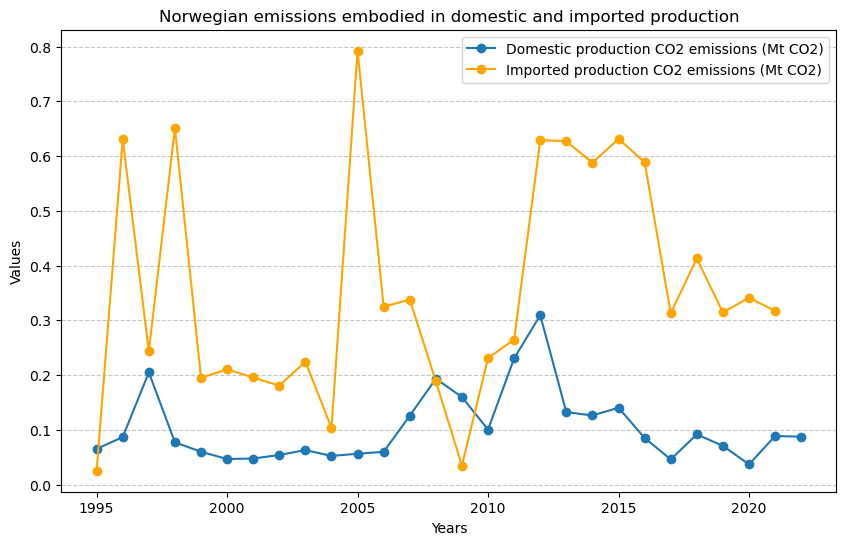

In [57]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production CO2 emissions (Mt CO2)'], marker='o', label='Domestic production CO2 emissions (Mt CO2)')
plt.plot(prod_co2_pd.index, prod_co2_pd['CO2 emissions due to importations (Mt CO2)'], marker='o', label='Imported production CO2 emissions (Mt CO2)', color='orange')
plt.title("Norwegian emissions embodied in domestic and imported production")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

Let's plot this result in percentage:

In [58]:
prod_co2_pd['Percentage domestic prod'] = prod_co2_pd['Domestic production CO2 emissions (Mt CO2)']*100 / environmental_impact_pd['Air emissions (Mt CO2)']
prod_co2_pd['Percentage import prod'] = prod_co2_pd['CO2 emissions due to importations (Mt CO2)']*100 / environmental_impact_pd['Air emissions (Mt CO2)']

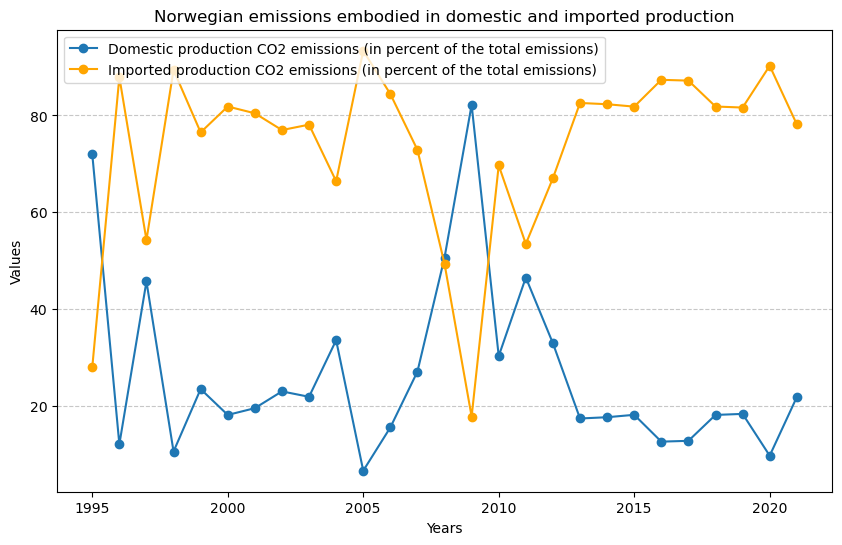

In [59]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Percentage domestic prod'], marker='o', label='Domestic production CO2 emissions (in percent of the total emissions)')
plt.plot(prod_co2_pd.index, prod_co2_pd['Percentage import prod'], marker='o', label='Imported production CO2 emissions (in percent of the total emissions)', color='orange')
plt.title("Norwegian emissions embodied in domestic and imported production")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We export the data

In [86]:
path_27 = path_file + '/data_processed/Part 3/percentage_domestic_imported.xlsx'
prod_co2_pd.to_excel(path_27)

#### Plot of Water Impact

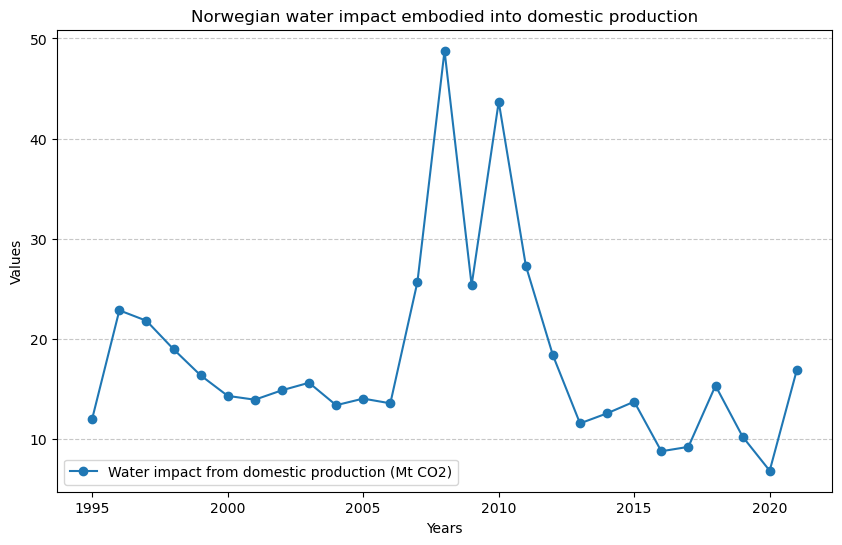

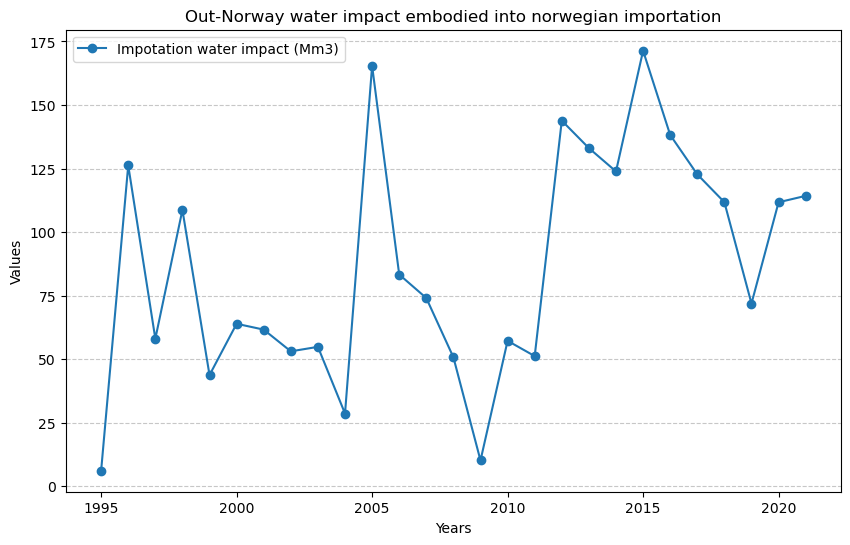

In [84]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production water consumption (Mm3)'], marker='o', label='Water impact from domestic production (Mt CO2)')
plt.title("Norwegian water impact embodied into domestic production")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Water consumption due to importations (Mm3)'], marker='o', label='Impotation water impact (Mm3)')
plt.title("Out-Norway water impact embodied into norwegian importation")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We export the data

In [87]:
path_28 = path_file + '/data_processed/Part 3/tot_water_impact.xlsx'
prod_co2_pd.to_excel(path_28)

#### Plot of land use impact

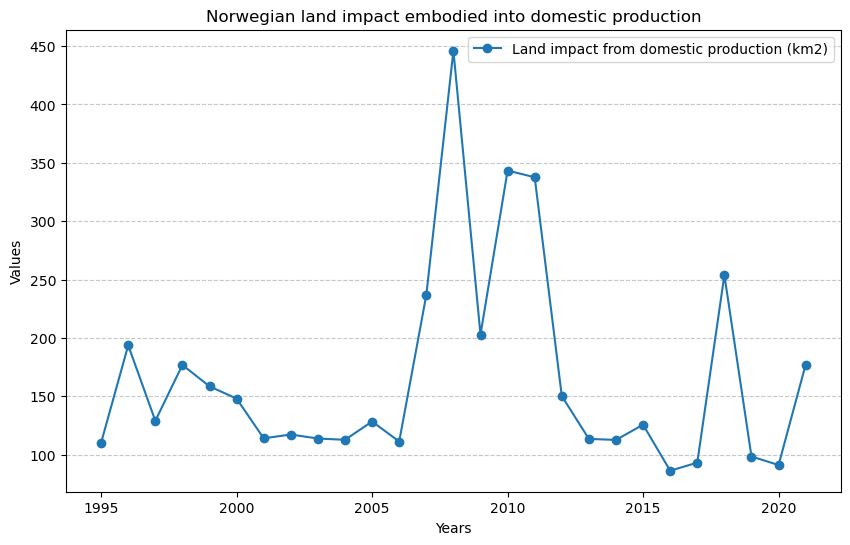

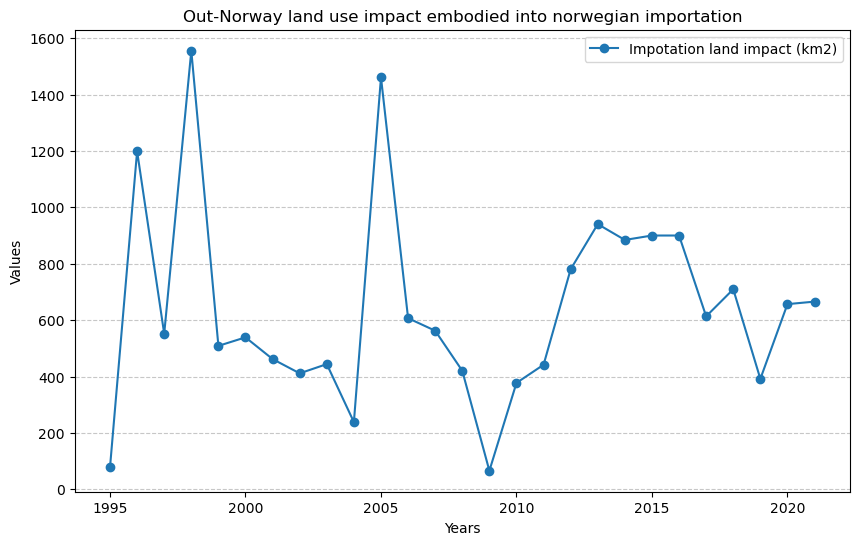

In [88]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production land use (km2)'], marker='o', label='Land impact from domestic production (km2)')
plt.title("Norwegian land impact embodied into domestic production")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()


plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Land use due to importations (km2)'], marker='o', label='Impotation land impact (km2)')
plt.title("Out-Norway land use impact embodied into norwegian importation")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We export the data

In [89]:
path_29 = path_file + '/data_processed/Part 3/tot_land_impact.xlsx'
prod_co2_pd.to_excel(path_29)

### Comparison between the Norwegian CO2 emissions embodied into domestic production vs top 3 countries importers

We can do the same with the top 3 countries that import in Norway to be able to compare with the graph in the papers

In [90]:
top_sum_production_country_3 = sum_production_country.iloc[1:4].index.tolist()
print(top_sum_production_country_3)
for i in range(len(year)):
    YEAR = year[i]
    try:
        # Extraction of the data
        x_year = exio_meta_dict[(str(YEAR),'x')].copy()
        Y_year = exio_meta_dict[(str(YEAR),'Y')].copy()
        index_col = x_year[x_year['indout'] == 0].index.tolist()
        new_Y_year = Y_year.drop(index_col).copy()
        y_clothes_year = np.zeros(len(new_Y_year))
        index_clothing_year = new_Y_year.index.get_level_values(1) == 'Manufacture of textiles (17)'
        y_clothes_year[index_clothing_year] = new_Y_year.loc[(slice(None), 'Manufacture of textiles (17)'), ('NO', 'Final consumption expenditure by households')].to_numpy()
        L_year = matrix_env_dict[(str(YEAR), 'L')].copy()
        
        S_year_airem_data = matrix_env_dict[(str(YEAR), 'S_airem')].copy()
        S_year_water_data = matrix_env_dict[(str(YEAR), 'S_water')].copy()
        S_year_landuse_data = matrix_env_dict[(str(YEAR), 'S_land')].copy()

        index_col_S_airem_year = exio_meta_dict[(str(YEAR), 'F_airem')].index.tolist()
        index_col_S_water_year = exio_meta_dict[(str(YEAR), 'F_water')].index.tolist()
        index_col_S_landuse_year = exio_meta_dict[(str(YEAR), 'F_land')].index.tolist()

        S_year_airem = pd.DataFrame(S_year_airem_data, index=index_col_S_airem_year, columns=new_Y_year.index)
        S_year_water = pd.DataFrame(S_year_water_data, index=index_col_S_water_year, columns=new_Y_year.index)
        S_year_landuse = pd.DataFrame(S_year_landuse_data, index=index_col_S_landuse_year, columns=new_Y_year.index)

        S_year_airem_filtred = S_year_airem[S_year_airem.index.str.startswith('CO2 - combustion - air')].sum(axis=0)
        S_year_water_filtred = S_year_water[S_year_water.index.str.startswith('Water Consumption')].sum(axis=0)
        S_year_landuse_filtred = S_year_landuse.sum(axis=0)

        # We create our y vector
        y_clothes_year = np.zeros(len(new_Y_year),)
        index_to_find_1 = (top_sum_production_country_3[0], 'Manufacture of textiles (17)') # First country
        index_to_find_2 = (top_sum_production_country_3[1], 'Manufacture of textiles (17)')
        index_to_find_3 = (top_sum_production_country_3[2], 'Manufacture of textiles (17)')

        if index_to_find_1 in new_Y_year.index and index_to_find_2 in new_Y_year.index and index_to_find_3 in new_Y_year.index:
            index_clothing_year_1 = new_Y_year.index.get_loc(index_to_find_1)
            index_clothing_year_2 = new_Y_year.index.get_loc(index_to_find_2)
            index_clothing_year_3 = new_Y_year.index.get_loc(index_to_find_3)
            col_to_use = ('NO', 'Final consumption expenditure by households')

            if col_to_use in new_Y_year.columns:
                y_clothes_year[index_clothing_year_1] = new_Y_year.loc[index_to_find_1, col_to_use]
                y_clothes_year[index_clothing_year_2] = new_Y_year.loc[index_to_find_2, col_to_use]
                y_clothes_year[index_clothing_year_3] = new_Y_year.loc[index_to_find_3, col_to_use]
            else:
                raise KeyError(f"Colonne {col_to_use} absente")
        else:
            raise KeyError(f"Secteur {index_to_find} absent")

        # we calculate the environmental impacts
        Delta_clothes_year_airem = S_year_airem_filtred @ L_year @ y_clothes_year* 1e-9
        Delta_clothes_year_water = S_year_water_filtred @ L_year @ y_clothes_year
        Delta_clothes_year_landuse = S_year_landuse_filtred @ L_year @ y_clothes_year
        # Final dataframe
        prod_co2_pd.loc[YEAR, 'CO2 emissions due to importations of the top 3 countries (Mt CO2)'] = Delta_clothes_year_airem.sum()
        prod_co2_pd.loc[YEAR, 'Water consumption due to importations of the top 3 countries (Mm3)'] = Delta_clothes_year_water.sum()
        prod_co2_pd.loc[YEAR, 'Land use due to importations of the top 3 countries (km2)'] = Delta_clothes_year_landuse.sum()
    except Exception as e:
        print(f"Année {YEAR} ignorée : {e}")

['CN', 'SE', 'WA']
Année 2022 ignorée : ('2022', 'S_land')


Let's plot the graphs:

#### For carbon emissions

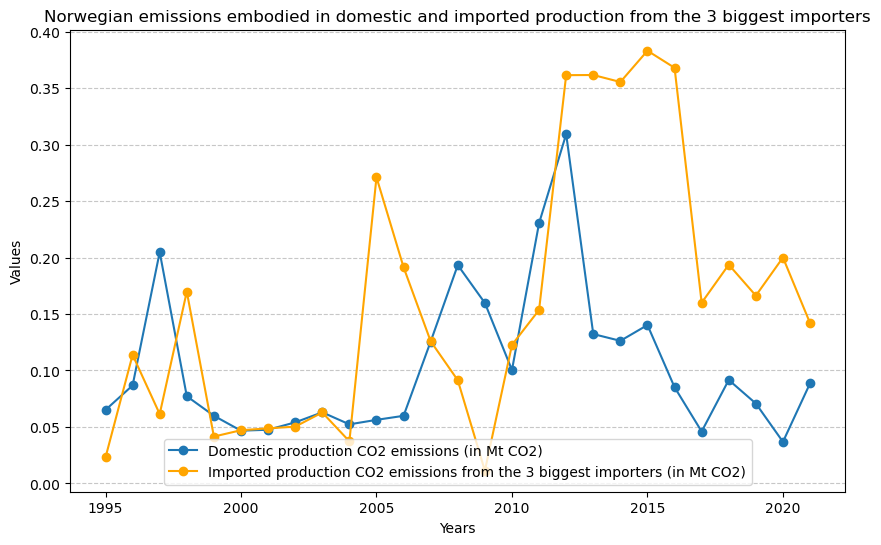

In [94]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production CO2 emissions (Mt CO2)'], marker='o', label='Domestic production CO2 emissions (in Mt CO2)')
plt.plot(prod_co2_pd.index, prod_co2_pd['CO2 emissions due to importations of the top 3 countries (Mt CO2)'], marker='o', label='Imported production CO2 emissions from the 3 biggest importers (in Mt CO2)', color='orange')
plt.title("Norwegian emissions embodied in domestic and imported production from the 3 biggest importers")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

Let's export the data:

In [95]:
path_30 = path_file + '/data_processed/Part 3/CO2em_domestic_imported_top_3.xlsx'
prod_co2_pd.to_excel(path_30)

#### For water consumption

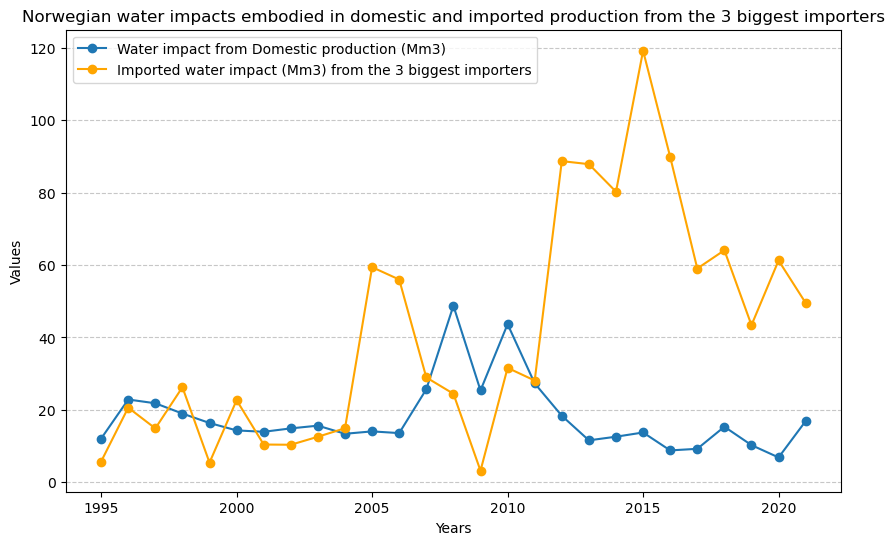

In [96]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production water consumption (Mm3)'], marker='o', label='Water impact from Domestic production (Mm3)')
plt.plot(prod_co2_pd.index, prod_co2_pd['Water consumption due to importations of the top 3 countries (Mm3)'], marker='o', label='Imported water impact (Mm3) from the 3 biggest importers', color='orange')
plt.title("Norwegian water impacts embodied in domestic and imported production from the 3 biggest importers")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

Let's import the data

In [97]:
path_31 = path_file + '/data_processed/Part 3/water_impact_domestic_imported_top_3.xlsx'
prod_co2_pd.to_excel(path_31)

#### Land use

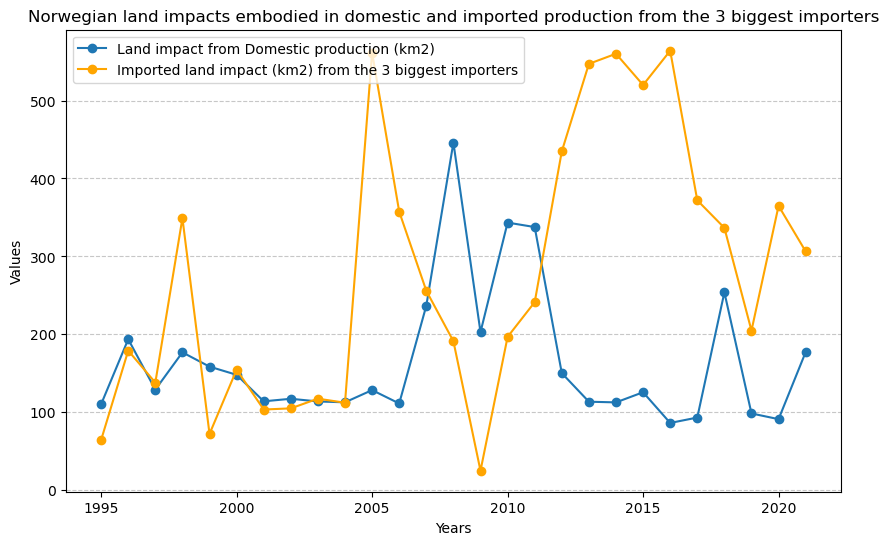

In [98]:
plt.figure(figsize=(10, 6))
plt.plot(prod_co2_pd.index, prod_co2_pd['Domestic production land use (km2)'], marker='o', label='Land impact from Domestic production (km2)')
plt.plot(prod_co2_pd.index, prod_co2_pd['Land use due to importations of the top 3 countries (km2)'], marker='o', label='Imported land impact (km2) from the 3 biggest importers', color='orange')
plt.title("Norwegian land impacts embodied in domestic and imported production from the 3 biggest importers")
plt.xlabel("Years")
plt.ylabel("Values")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend()
plt.show()

We extract the data:

In [99]:
path_32 = path_file + '/data_processed/Part 3/land_impact_domestic_imported_top_3.xlsx'
prod_co2_pd.to_excel(path_32)